# Skeleton + graph healing (unified)

Input: `outputs/<masks folder>/{id}_pred.png` from **Phase I unified** — folder picked via `MODEL_NAME`, same as the Phase I notebook.
Output: `outputs/graphs_<tag>/{id}_graph.json`

**CPU is enough — no training here, just geometry + NetworkX.** Set your Colab runtime type to CPU (Runtime → Change runtime type → None) before running this notebook — it doesn't need a GPU, so running it on CPU saves your GPU quota for Phase I.

Masks must already exist for whichever `MODEL_NAME` you pick below — run that model in the Phase I unified notebook first (or SAM mask repair, if you're reading repaired masks).


## Mount Drive

Graphs, visualizations, and (if you choose the Drive fallback below) the dataset all live on Drive so they persist across sessions.

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## Dataset — reuse from this session, or re-download

Phase I unified downloads DeepGlobe to **ephemeral** local storage (`/content/data/train`), not Drive. That means:

- **Same runtime, right after Phase I** → the files are still on disk, nothing to do here.
- **Fresh runtime / new session** → that local copy is gone, so this cell re-downloads it via the Kaggle API (identical to the Phase I unified cell). Skip it only if you've pointed `DATA_DIR` below at a Drive copy instead.


In [2]:
import os, subprocess, zipfile

LOCAL_DATA_ROOT = "/content/data"
LOCAL_TRAIN_DIR = f"{LOCAL_DATA_ROOT}/train"

if not os.path.isdir(LOCAL_TRAIN_DIR) or not os.listdir(LOCAL_TRAIN_DIR):
    subprocess.run(["pip", "install", "-q", "kaggle"], check=True)

    os.makedirs("/root/.kaggle", exist_ok=True)
    if not os.path.exists("/root/.kaggle/kaggle.json"):
        from google.colab import files
        print("Upload your kaggle.json API token:")
        uploaded = files.upload()
        for fname in uploaded:
            os.rename(fname, "/root/.kaggle/kaggle.json")
    os.chmod("/root/.kaggle/kaggle.json", 0o600)

    KAGGLE_DATASET = "balraj98/deepglobe-road-extraction-dataset"  # match Phase I unified
    os.makedirs(LOCAL_DATA_ROOT, exist_ok=True)
    subprocess.run(
        ["kaggle", "datasets", "download", "-d", KAGGLE_DATASET, "-p", LOCAL_DATA_ROOT],
        check=True,
    )
    zips = [f for f in os.listdir(LOCAL_DATA_ROOT) if f.endswith(".zip")]
    with zipfile.ZipFile(f"{LOCAL_DATA_ROOT}/{zips[0]}") as zf:
        zf.extractall(LOCAL_DATA_ROOT)
    print("Extracted to", LOCAL_DATA_ROOT)
else:
    print("Local data already present at", LOCAL_TRAIN_DIR)

print("Local train dir:", LOCAL_TRAIN_DIR)


Upload your kaggle.json API token:


Saving kaggle.json to kaggle.json
Extracted to /content/data
Local train dir: /content/data/train


## Install packages

In [3]:
import subprocess
subprocess.run([
    "pip", "install", "-q",
    "scikit-image",
    "networkx",
    "opencv-python",
    "matplotlib",
    "tqdm",
])
print("packages ok")


packages ok


## Model switch — pick which Phase I output to heal

Set `MODEL_NAME` to whichever model you trained in Phase I unified (`deeplabv3`, `unetpp`, `unext`, `segformer`, `dinov2`, `mfuser`), or `sam_repaired` to read SAM-repaired masks instead. Mask-folder names match the Phase I unified notebook's `MODEL_CONFIGS` exactly, so this always points at the right masks without manual path edits.


In [ ]:
import os

MODEL_NAME = "sam_repaired"  # deeplabv3 | unetpp | unext | segformer | dinov2 | mfuser | sam_repaired

# Same mask_dir values as Phase I unified's MODEL_CONFIGS — keep these two in sync if you rename folders.
MASK_DIR_BY_MODEL = {
    "deeplabv3":    "masks_deeplab",
    "unetpp":       "masks_unetpp",
    "unext":        "masks_unext",
    "segformer":    "masks_segformer",
    "dinov2":       "masks_dinov2",
    "mfuser":       "masks_mfuser",
    "sam_repaired": "masks_sam_repaired",
}
MODEL_TAG = MODEL_NAME  # used in output folder names, plot titles, filenames

DRIVE_BASE = "/content/drive/MyDrive/RouteResilience"
DATA_DIR   = LOCAL_TRAIN_DIR  # from the dataset cell above; point at a Drive path instead if you skipped that cell
MASK_DIR   = "/content/drive/MyDrive/RouteResilience/outputs/masks_deeplab"
GRAPH_DIR  = f"{DRIVE_BASE}/outputs/graphs_{MODEL_TAG}"
VIS_DIR    = f"{DRIVE_BASE}/outputs/visualizations_{MODEL_TAG}"

for d in [GRAPH_DIR, VIS_DIR]:
    os.makedirs(d, exist_ok=True)

if not os.path.isdir(MASK_DIR):
    raise FileNotFoundError(
        f"MASK_DIR not found: {MASK_DIR}\n"
        f"Run MODEL_NAME='{MODEL_NAME}' in the Phase I unified notebook (inference cell) first."
    )

# Phase II hyperparameters
MAX_BRIDGE_DIST  = 40
MAX_ANGLE_DIFF   = 35
MIN_ROAD_AREA    = 80
MIN_EDGE_LENGTH  = 10
MIN_SPUR_LENGTH = 15

# Demo samples — only processed if mask file exists
PROCESS_IDS = ["493626", "477671", "422265", "194764"]

print(f"Model     : {MODEL_NAME}")
print(f"Data dir  : {DATA_DIR}")
print(f"Mask dir  : {MASK_DIR}")
print(f"Graph dir : {GRAPH_DIR}")
print(f"Vis dir   : {VIS_DIR}")
print(f"Samples   : {PROCESS_IDS}")


Model     : sam_repaired
Data dir  : /content/data/train
Mask dir  : /content/drive/MyDrive/RouteResilience/outputs/masks_deeplab
Graph dir : /content/drive/MyDrive/RouteResilience/outputs/graphs_sam_repaired
Vis dir   : /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired
Samples   : ['493626', '477671', '422265', '194764']


## Skeletonization + graph extraction + healing

Unchanged from the original Phase II notebook — geometry/NetworkX logic doesn't depend on which model produced the mask.

In [21]:
import math
import json
import numpy as np
import cv2
import networkx as nx
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize, remove_small_objects


def preprocess_mask(mask, min_area=MIN_ROAD_AREA):
    """Close small gaps and remove noise blobs."""
    mask = (mask > 127).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask_bool = remove_small_objects(mask.astype(bool), min_size=min_area)
    return mask_bool.astype(np.uint8)


def extract_skeleton(mask):
    clean = preprocess_mask(mask)
    skel = skeletonize(clean > 0)
    return skel.astype(np.uint8), clean


def neighbors8(r, c, h, w):
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            if dr == 0 and dc == 0:
                continue
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w:
                yield nr, nc


def build_graph(skel):
    """
    Extract nodes at intersections (degree >= 3) and endpoints (degree == 1).
    Trace edges as polylines between nodes along degree-2 pixels.
    """
    h, w = skel.shape
    skel_set = set(zip(*np.where(skel > 0)))

    degree = {}
    for r, c in skel_set:
        degree[(r, c)] = sum(
            1 for nr, nc in neighbors8(r, c, h, w) if (nr, nc) in skel_set
        )

    node_pixels = {p for p, d in degree.items() if d != 2}
    G = nx.Graph()
    for i, (r, c) in enumerate(node_pixels):
        G.add_node(i, y=int(r), x=int(c), pixel=(r, c))

    pixel_to_node = {G.nodes[n]["pixel"]: n for n in G.nodes}
    visited = set()

    for start_node in G.nodes:
        sr, sc = G.nodes[start_node]["pixel"]
        for nr, nc in neighbors8(sr, sc, h, w):
            if (nr, nc) not in skel_set:
                continue
            key = tuple(sorted([(sr, sc), (nr, nc)]))
            if key in visited:
                continue

            path = [(sr, sc), (nr, nc)]
            pr, pc = sr, sc
            cr, cc = nr, nc

            while (cr, cc) not in node_pixels:
                nbrs = [
                    p for p in neighbors8(cr, cc, h, w)
                    if p in skel_set and p != (pr, pc)
                ]
                if not nbrs:
                    break
                pr, pc = cr, cc
                cr, cc = nbrs[0]
                path.append((cr, cc))

            if (cr, cc) in node_pixels:
                end_node = pixel_to_node[(cr, cc)]
                if start_node != end_node and len(path) >= MIN_EDGE_LENGTH:
                    G.add_edge(
                        start_node, end_node,
                        pts=path, length=float(len(path)), healed=False,
                    )
                    visited.add(key)

    return G


class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))
        self.rank = [0] * n

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        if self.rank[ra] < self.rank[rb]:
            ra, rb = rb, ra
        self.parent[rb] = ra
        if self.rank[ra] == self.rank[rb]:
            self.rank[ra] += 1
        return True


def endpoint_direction(G, node, lookahead=10):
    """Unit vector along the road leaving an endpoint (using local path tangent)."""
    nbrs = list(G.neighbors(node))
    if not nbrs:
        return (0.0, 0.0)

    nbr = nbrs[0]
    path = G[node][nbr]["pts"]
    pixel = G.nodes[node]["pixel"]

    # Check if the path array starts or ends with our current node
    if path[0] == pixel:
        # Path moves away from the node, look ahead positively
        idx = min(lookahead, len(path) - 1)
        target = path[idx]
    else:
        # Path moves towards the node, look ahead negatively (backwards)
        idx = max(0, len(path) - 1 - lookahead)
        target = path[idx]

    dr = target[0] - pixel[0]
    dc = target[1] - pixel[1]

    mag = math.hypot(dr, dc) or 1.0
    return (dr / mag, dc / mag)


def angle_between(v1, v2):
    dot = max(-1.0, min(1.0, v1[0] * v2[0] + v1[1] * v2[1]))
    return math.degrees(math.acos(dot))


# def heal_graph(G, max_dist=MAX_BRIDGE_DIST, max_angle=MAX_ANGLE_DIFF):
#     """
#     Bridge nearby aligned endpoints from different components.
#     Red edges in visualization = healed bridges.
#     """
#     endpoints = [n for n in G.nodes if G.degree(n) == 1]
#     if len(endpoints) < 2:
#         return G, []

#     uf = UnionFind(max(G.nodes) + 1 if G.nodes else 1)
#     for u, v in G.edges:
#         uf.union(u, v)

#     candidates = []
#     for i, n1 in enumerate(endpoints):
#         p1 = G.nodes[n1]["pixel"]
#         d1 = endpoint_direction(G, n1)
#         for n2 in endpoints[i + 1:]:
#             if uf.find(n1) == uf.find(n2):
#                 continue
#             p2 = G.nodes[n2]["pixel"]
#             dist = math.hypot(p1[0] - p2[0], p1[1] - p2[1])
#             if dist > max_dist:
#                 continue
#             d2 = endpoint_direction(G, n2)
#             ang = angle_between(d1, (-d2[0], -d2[1]))
#             if ang > max_angle:
#                 continue
#             weight = dist + ang * 0.5
#             candidates.append((weight, n1, n2, p1, p2))

#     candidates.sort()
#     bridges = []
#     for weight, n1, n2, p1, p2 in candidates:
#         if uf.union(n1, n2):
#             G.add_edge(n1, n2, pts=[p1, p2], length=weight, healed=True)
#             bridges.append({"source": n1, "target": n2, "weight": weight})

#     return G, bridges
def heal_graph(G, max_dist=MAX_BRIDGE_DIST, max_angle=MAX_ANGLE_DIFF):
    """
    Bridge nearby aligned endpoints.
    UnionFind constraint removed to allow intra-component loop healing for dense grids.
    Red edges in visualization = healed bridges.
    """
    endpoints = [n for n in G.nodes if G.degree(n) == 1]
    if len(endpoints) < 2:
        return G, []

    candidates = []
    for i, n1 in enumerate(endpoints):
        p1 = G.nodes[n1]["pixel"]
        d1 = endpoint_direction(G, n1)

        for n2 in endpoints[i + 1:]:
            # The UnionFind component check has been deliberately bypassed here
            p2 = G.nodes[n2]["pixel"]
            dist = math.hypot(p1[0] - p2[0], p1[1] - p2[1])

            if dist > max_dist:
                continue

            d2 = endpoint_direction(G, n2)
            ang = angle_between(d1, (-d2[0], -d2[1]))

            if ang > max_angle:
                continue

            weight = dist + ang * 0.5
            candidates.append((weight, n1, n2, p1, p2))

    candidates.sort()
    bridges = []

    # Replaced UnionFind with a local lock to prevent a single node from forming multiple conflicting bridges
    used = set()

    for weight, n1, n2, p1, p2 in candidates:
        if n1 not in used and n2 not in used:
            G.add_edge(n1, n2, pts=[p1, p2], length=weight, healed=True)
            bridges.append({"source": n1, "target": n2, "weight": weight})
            used.add(n1)
            used.add(n2)

    return G, bridges

def prune_spurs(G, min_spur_length=15):
    """Remove short dead-end branches — skeletonization noise, not real road endpoints."""
    changed = True
    while changed:
        changed = False
        for n in list(G.nodes):
            if G.degree(n) == 1:
                (u,) = list(G.neighbors(n))
                if G[n][u].get("length", 0) < min_spur_length:
                    G.remove_node(n)
                    changed = True
    # nodes left orphaned when build_graph dropped their edge for being too short
    G.remove_nodes_from([n for n in G.nodes if G.degree(n) == 0])
    return G
def conn_ratio(G):
    """Share of nodes in the largest component."""
    if G.number_of_nodes() == 0:
        return 0.0
    return len(max(nx.connected_components(G), key=len)) / G.number_of_nodes()





Chosen point (101,87) — 993 valid candidates, buffer=60px

[493626] Original conn=0.052 | Broken=0.052 | Healed=0.159 | Bridges=69


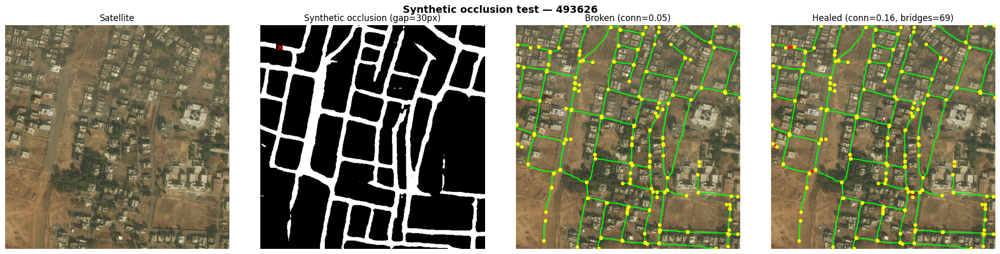

Chosen point (704,452) — 1291 valid candidates, buffer=60px

[477671] Original conn=0.094 | Broken=0.079 | Healed=0.127 | Bridges=14


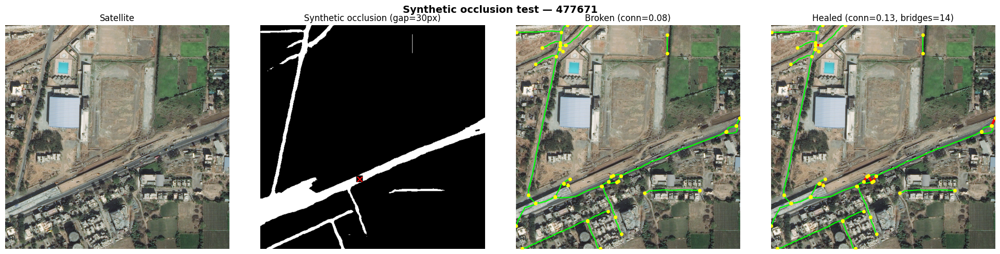

Chosen point (329,310) — 962 valid candidates, buffer=60px

[422265] Original conn=0.250 | Broken=0.200 | Healed=0.400 | Bridges=1


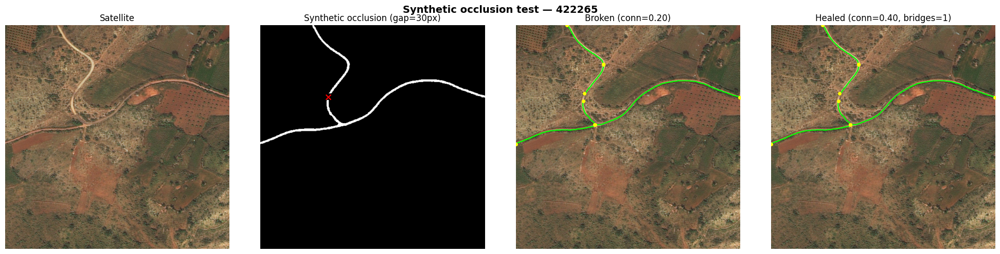

Chosen point (254,640) — 614 valid candidates, buffer=60px

[194764] Original conn=0.333 | Broken=0.250 | Healed=0.750 | Bridges=2


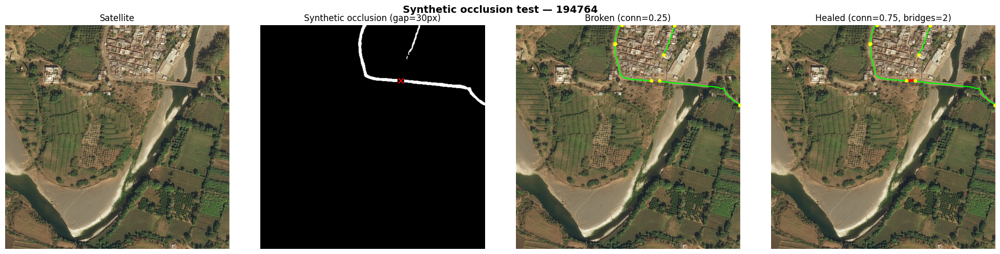

Chosen point (942,947) — 1658 valid candidates, buffer=60px

[393111] Original conn=0.051 | Broken=0.046 | Healed=0.200 | Bridges=17


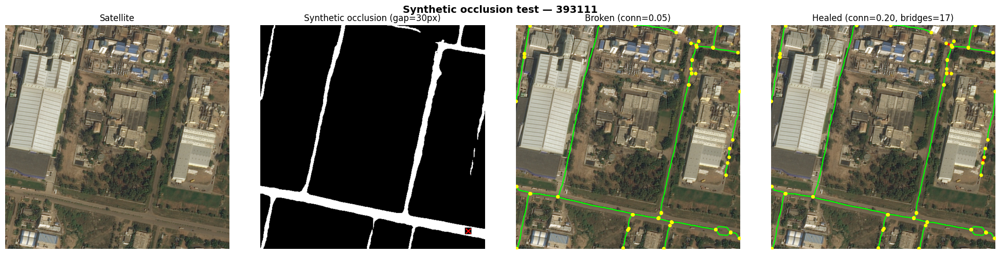

Chosen point (676,936) — 547 valid candidates, buffer=60px

[920694] Original conn=0.500 | Broken=0.333 | Healed=0.667 | Bridges=1


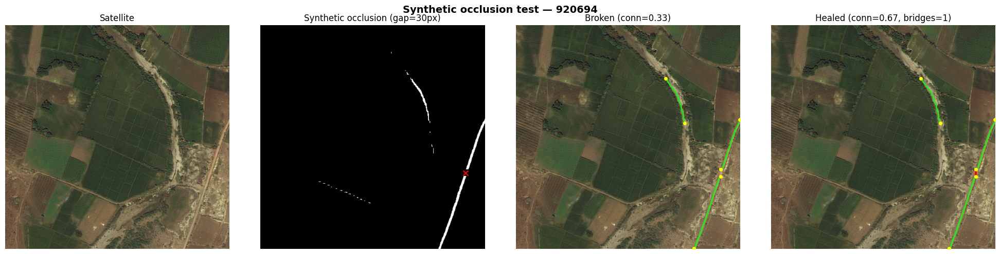

Chosen point (852,748) — 1272 valid candidates, buffer=60px

[356917] Original conn=0.029 | Broken=0.027 | Healed=0.143 | Bridges=48


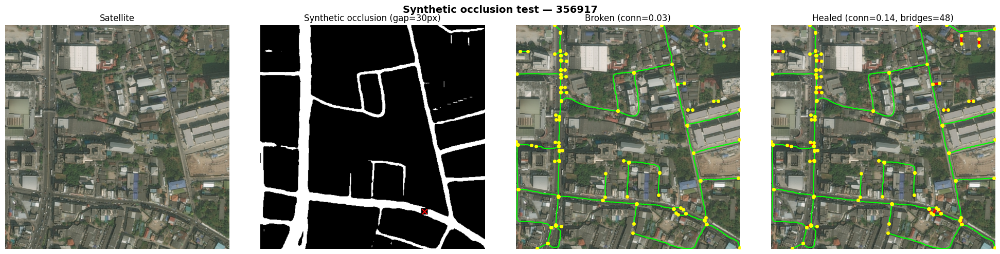

Chosen point (600,632) — 1195 valid candidates, buffer=60px

[434989] Original conn=0.176 | Broken=0.143 | Healed=0.238 | Bridges=3


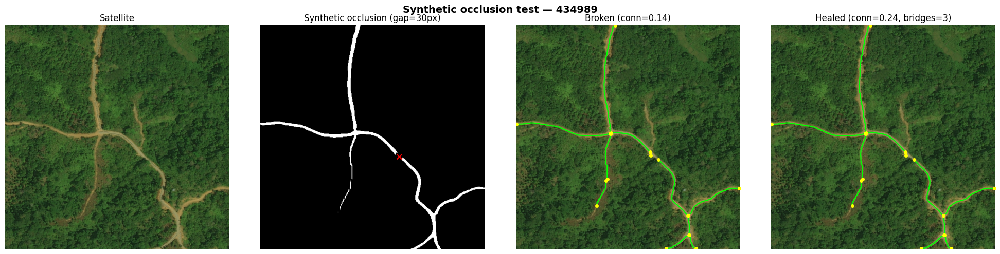

Chosen point (676,77) — 1803 valid candidates, buffer=60px

[511525] Original conn=0.054 | Broken=0.053 | Healed=0.211 | Bridges=24


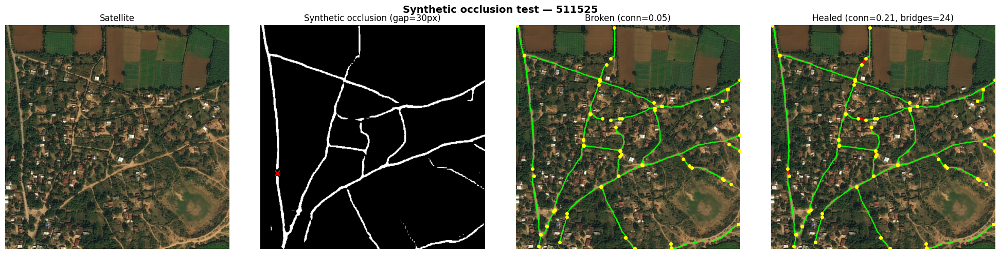

Chosen point (344,966) — 377 valid candidates, buffer=60px

[961236] Original conn=1.000 | Broken=0.500 | Healed=0.500 | Bridges=0


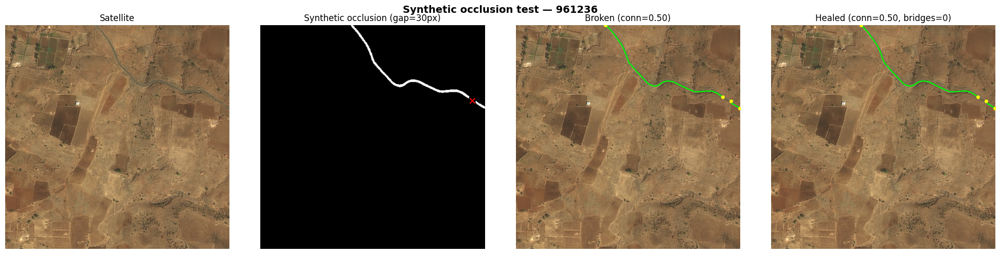

Chosen point (420,228) — 475 valid candidates, buffer=60px

[817650] Original conn=0.077 | Broken=0.073 | Healed=0.220 | Bridges=13


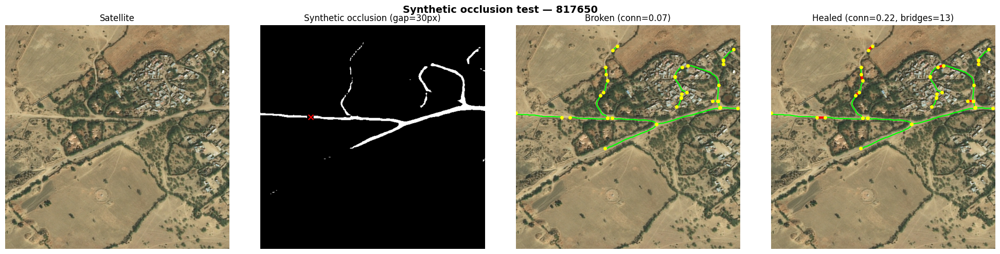

Chosen point (279,666) — 1727 valid candidates, buffer=60px

[161528] Original conn=0.032 | Broken=0.031 | Healed=0.177 | Bridges=30


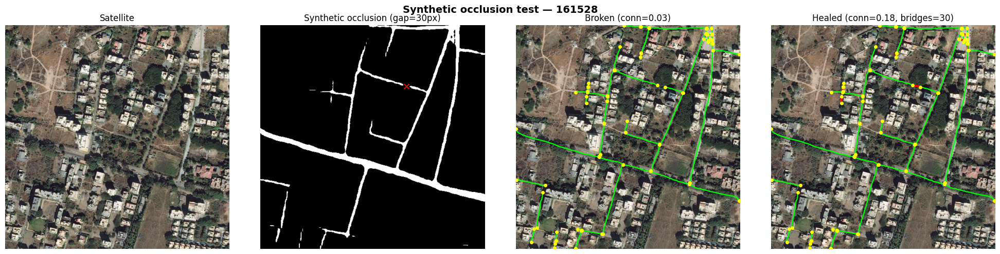

Chosen point (486,293) — 1874 valid candidates, buffer=60px

[684145] Original conn=0.035 | Broken=0.034 | Healed=0.147 | Bridges=30


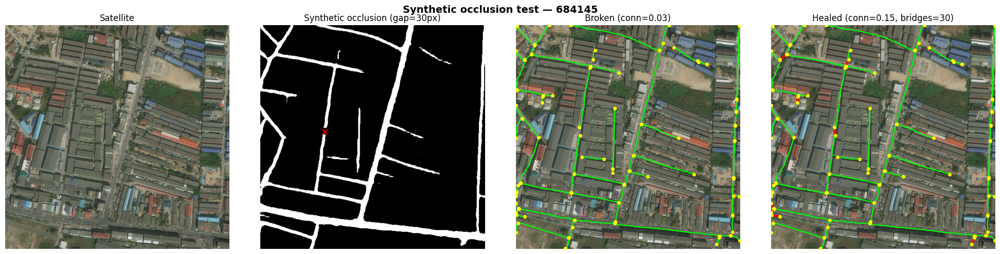

Chosen point (962,334) — 725 valid candidates, buffer=60px

[816528] Original conn=0.120 | Broken=0.111 | Healed=0.259 | Bridges=5


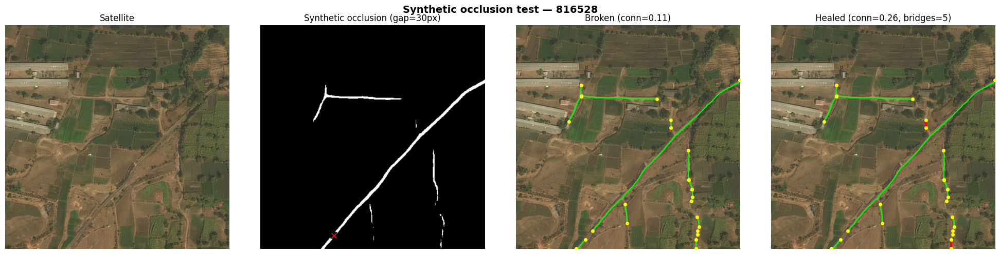

Chosen point (376,590) — 1237 valid candidates, buffer=60px

[942296] Original conn=0.047 | Broken=0.046 | Healed=0.206 | Bridges=35


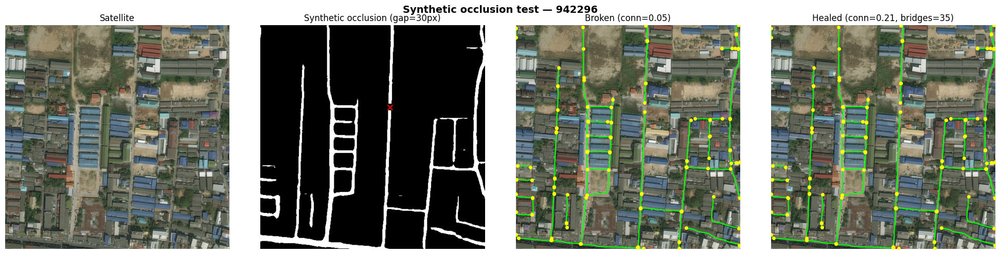

Chosen point (323,637) — 972 valid candidates, buffer=60px

[127572] Original conn=1.000 | Broken=0.500 | Healed=1.000 | Bridges=1


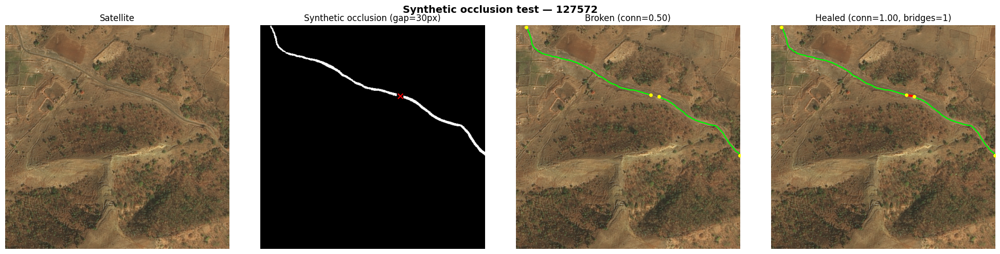

Chosen point (449,54) — 594 valid candidates, buffer=60px

[420624] Original conn=0.111 | Broken=0.103 | Healed=0.276 | Bridges=6


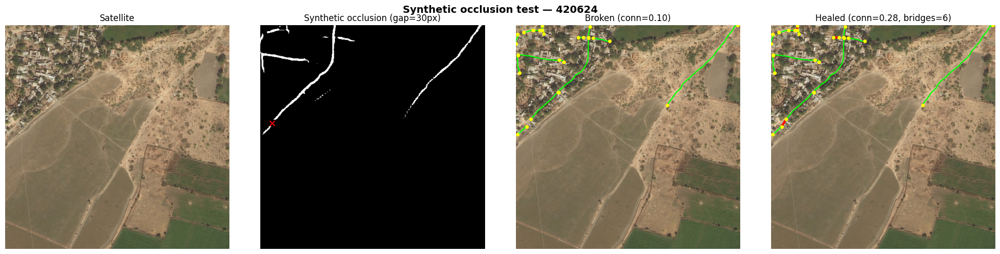

Chosen point (653,884) — 674 valid candidates, buffer=60px

[109889] Original conn=0.055 | Broken=0.053 | Healed=0.228 | Bridges=15


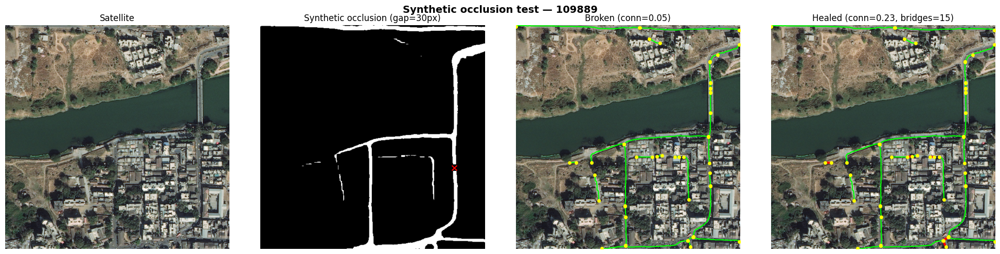

Chosen point (473,677) — 860 valid candidates, buffer=60px

[825359] Original conn=0.081 | Broken=0.077 | Healed=0.154 | Bridges=7


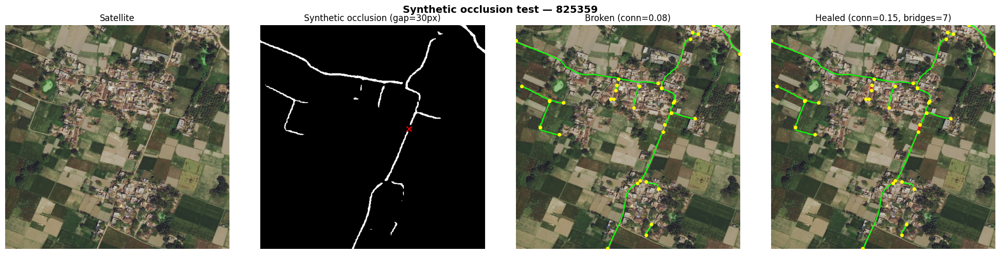

Chosen point (143,120) — 55 valid candidates, buffer=60px

[44614] Original conn=0.143 | Broken=0.125 | Healed=0.250 | Bridges=4


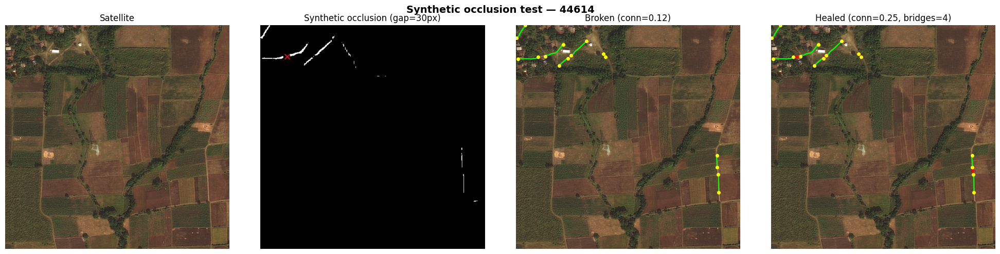

Chosen point (442,778) — 1711 valid candidates, buffer=60px

[445532] Original conn=0.037 | Broken=0.036 | Healed=0.117 | Bridges=24


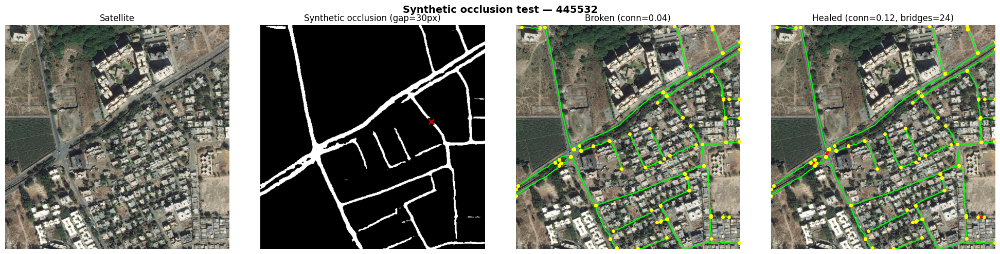

Chosen point (519,313) — 1341 valid candidates, buffer=60px

[774511] Original conn=0.500 | Broken=0.333 | Healed=0.667 | Bridges=1


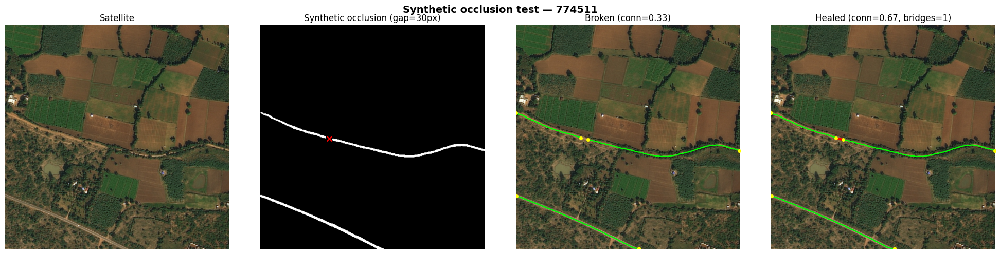

Chosen point (35,916) — 71 valid candidates, buffer=60px

[993412] Original conn=0.250 | Broken=0.200 | Healed=0.200 | Bridges=2


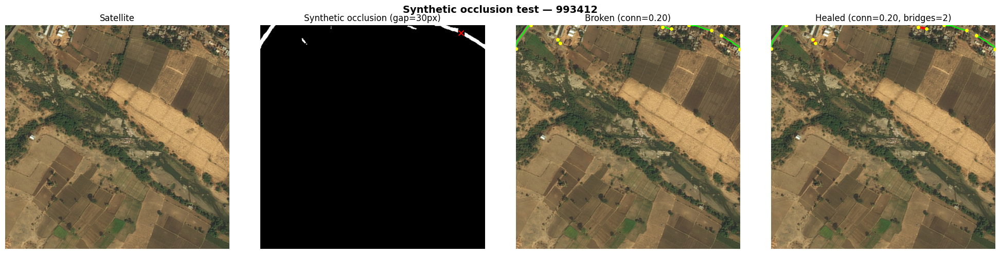

Chosen point (507,359) — 1128 valid candidates, buffer=60px

[54635] Original conn=0.200 | Broken=0.167 | Healed=0.333 | Bridges=2


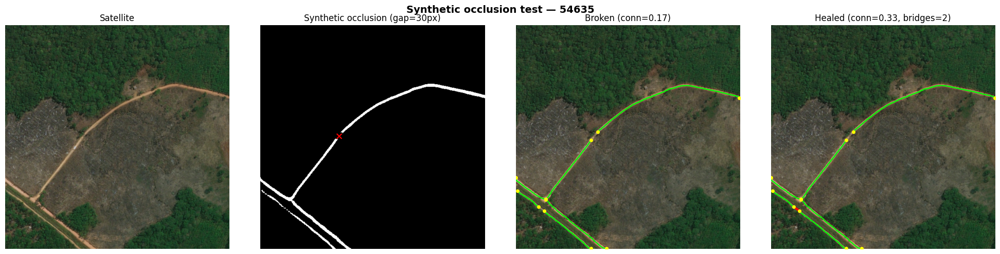

Chosen point (636,787) — 1407 valid candidates, buffer=60px

[77085] Original conn=0.044 | Broken=0.043 | Healed=0.114 | Bridges=14


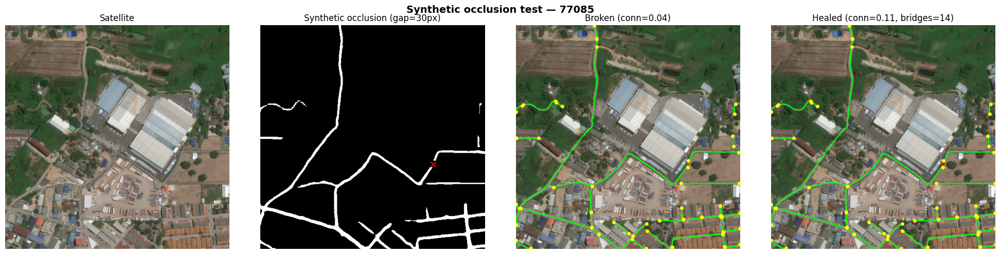

Chosen point (691,68) — 1305 valid candidates, buffer=60px

[666341] Original conn=0.085 | Broken=0.082 | Healed=0.131 | Bridges=14


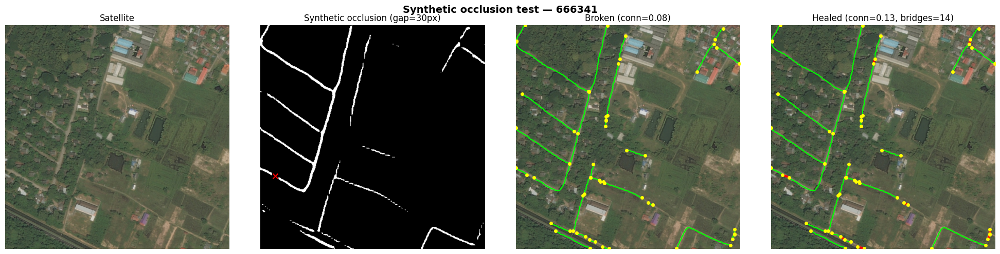

Chosen point (662,132) — 1882 valid candidates, buffer=60px

[906484] Original conn=0.037 | Broken=0.036 | Healed=0.116 | Bridges=33


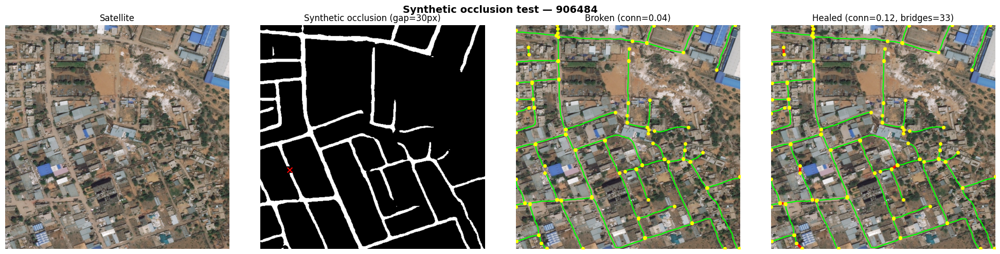

Chosen point (987,475) — 452 valid candidates, buffer=60px

[375903] Original conn=1.000 | Broken=0.500 | Healed=1.000 | Bridges=1


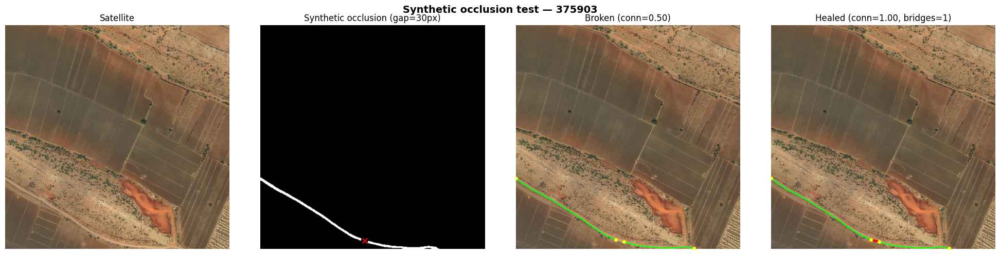

Chosen point (759,982) — 296 valid candidates, buffer=60px

[392410] Original conn=0.333 | Broken=0.250 | Healed=0.500 | Bridges=2


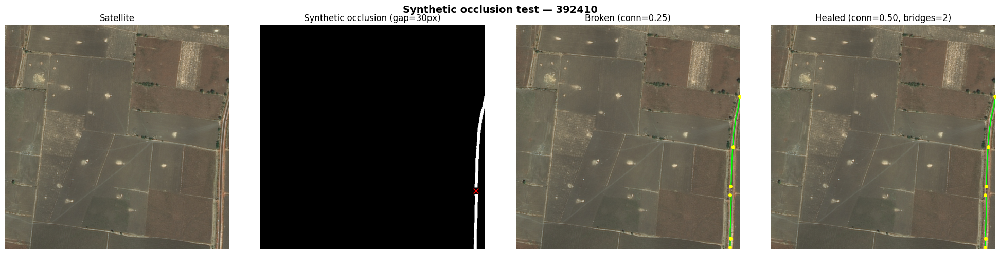

Chosen point (921,627) — 901 valid candidates, buffer=60px

[632438] Original conn=1.000 | Broken=0.500 | Healed=0.500 | Bridges=0


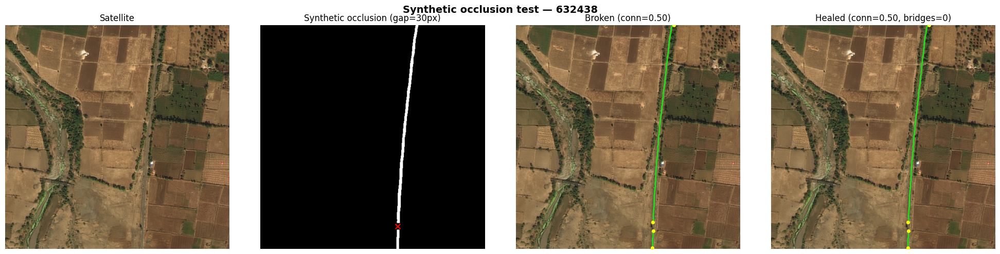

Chosen point (321,261) — 1608 valid candidates, buffer=60px

[452636] Original conn=0.208 | Broken=0.192 | Healed=0.346 | Bridges=3


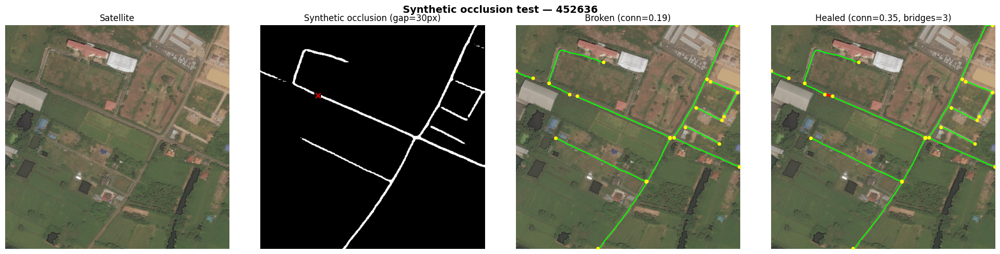

Chosen point (238,248) — 905 valid candidates, buffer=60px

[919932] Original conn=0.500 | Broken=0.333 | Healed=0.667 | Bridges=1


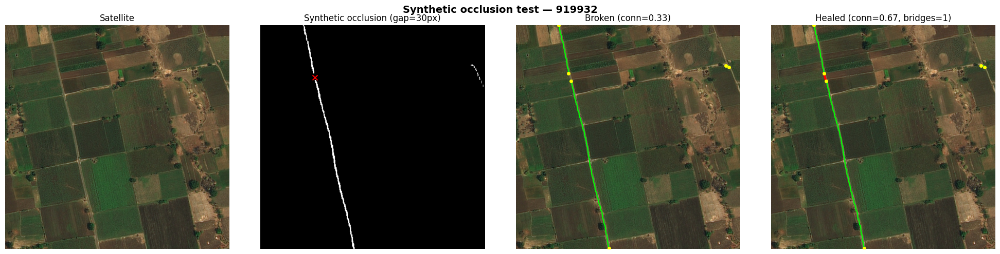

Chosen point (65,725) — 1340 valid candidates, buffer=60px

[55062] Original conn=0.036 | Broken=0.035 | Healed=0.106 | Bridges=35


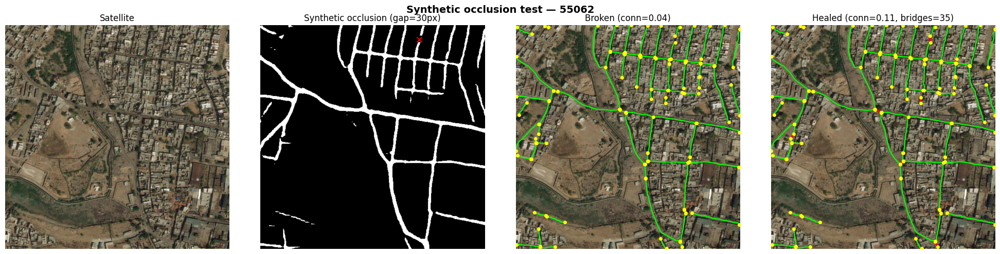

Chosen point (244,414) — 1475 valid candidates, buffer=60px

[502218] Original conn=0.043 | Broken=0.042 | Healed=0.063 | Bridges=20


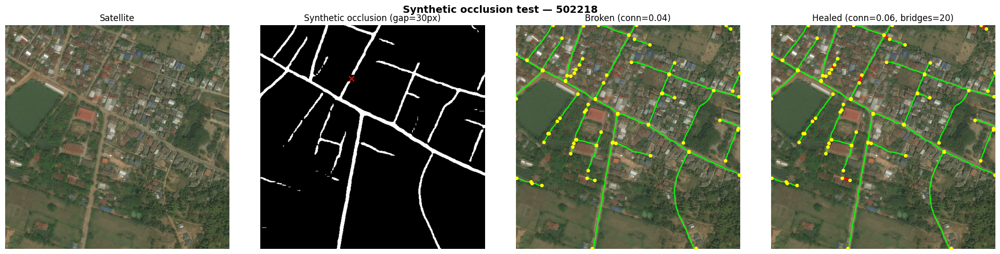

Chosen point (195,366) — 928 valid candidates, buffer=60px

[44984] Original conn=0.143 | Broken=0.130 | Healed=0.565 | Bridges=7


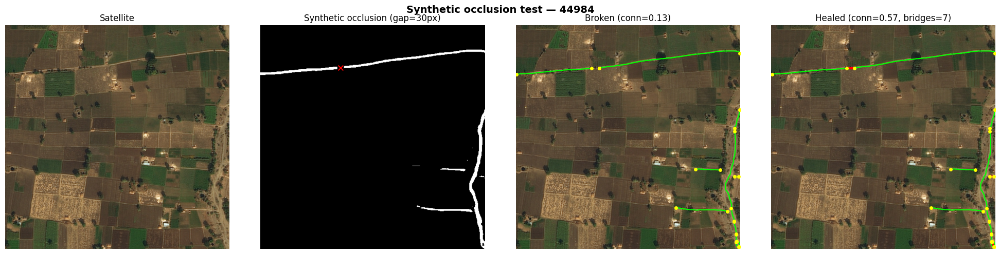

Chosen point (418,459) — 673 valid candidates, buffer=60px

[790349] Original conn=0.021 | Broken=0.020 | Healed=0.102 | Bridges=24


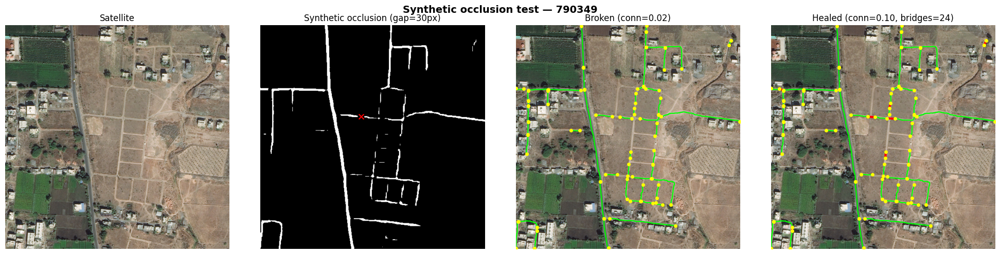

Chosen point (919,654) — 759 valid candidates, buffer=60px

[597644] Original conn=1.000 | Broken=0.500 | Healed=1.000 | Bridges=1


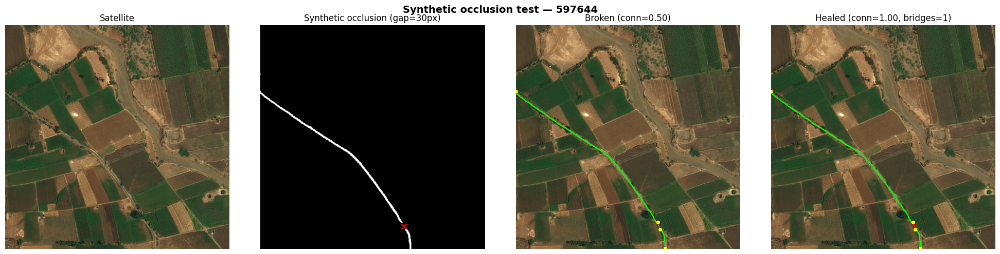

Chosen point (696,926) — 770 valid candidates, buffer=60px

[616654] Original conn=0.333 | Broken=0.250 | Healed=0.250 | Bridges=2


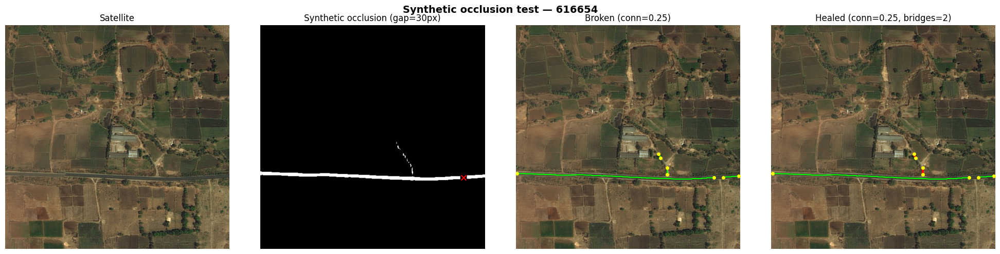

Chosen point (632,896) — 1770 valid candidates, buffer=60px

[188924] Original conn=0.062 | Broken=0.056 | Healed=0.122 | Bridges=22


In [ ]:
import os
import math
import matplotlib.pyplot as plt
import cv2
import numpy as np

def punch_synthetic_gap(mask, gap_size=30, seed=0, junction_buffer=2.0):
    """Zero out a square patch centered on a mid-segment pixel of the LARGEST
    connected skeleton component only — avoids stray/pre-broken fragments."""
    skel = skeletonize(mask > 127)
    h, w = skel.shape
    skel_set = set(zip(*np.where(skel)))

    degree = {
        (r, c): sum(1 for nr, nc in neighbors8(r, c, h, w) if (nr, nc) in skel_set)
        for r, c in skel_set
    }
    junctions = {p for p, d in degree.items() if d != 2}

    # keep only the largest connected piece of the skeleton (ignore stray fragments)
    G_all = build_graph(skel)
    if G_all.number_of_nodes() == 0:
        raise ValueError("empty skeleton")
    largest_cc = max(nx.connected_components(G_all), key=len)
    largest_pixels = {G_all.nodes[n]["pixel"] for n in largest_cc}
    # expand to all skeleton pixels reachable from these nodes (rough: just use full skel_set
    # since fragments are typically small and won't dominate candidates once we also require
    # a safe distance from EVERY junction, including fragment endpoints)

    margin = gap_size
    min_dist = gap_size * junction_buffer  # bigger buffer than before
    candidates = [
        (r, c) for (r, c), d in degree.items()
        if d == 2
        and margin < r < h - margin and margin < c < w - margin
        and all(math.hypot(r - jr, c - jc) > min_dist for jr, jc in junctions)
    ]
    if not candidates:
        raise ValueError("No clean mid-segment location found — try smaller gap_size/junction_buffer")

    rng = np.random.default_rng(seed)
    cy, cx = candidates[rng.integers(len(candidates))]
    occluded = mask.copy()
    half = gap_size // 2
    occluded[cy - half:cy + half, cx - half:cx + half] = 0
    print(f"Chosen point ({cy},{cx}) — {len(candidates)} valid candidates, buffer={min_dist:.0f}px")
    return occluded, (cy, cx)

GAP_SIZE = 30  # px — bigger than the road's width so the cut fully severs it

# Optional: Create a folder to save these specific tests if you need them for your report
SYNTH_VIS_DIR = f"{DRIVE_BASE}/outputs/synthetic_tests_{MODEL_TAG}"
os.makedirs(SYNTH_VIS_DIR, exist_ok=True)

# Loop through all available IDs
for img_id in PROCESS_IDS:
    mask_path = f"{MASK_DIR}/{img_id}_pred.png"
    sat_path  = f"{DATA_DIR}/{img_id}_sat.jpg"

    if not os.path.exists(mask_path) or not os.path.exists(sat_path):
        print(f"Skipping {img_id} — files not found.")
        continue

    orig_mask = cv2.imread(mask_path, 0)
    sat_img = cv2.cvtColor(cv2.imread(sat_path), cv2.COLOR_BGR2RGB)

    if orig_mask.shape[:2] != sat_img.shape[:2]:
        orig_mask = cv2.resize(orig_mask, (sat_img.shape[1], sat_img.shape[0]), interpolation=cv2.INTER_NEAREST)

    # 1. confirm baseline is already continuous
    skel0, _ = extract_skeleton(orig_mask)
    G0 = prune_spurs(build_graph(skel0), MIN_SPUR_LENGTH)

    # 2. punch the synthetic gap (using the img_id to generate a unique random seed)
    try:
        occluded_mask, gap_center = punch_synthetic_gap(orig_mask, gap_size=GAP_SIZE, seed=int(img_id) % 1000)
    except ValueError:
        print(f"--- Skipping {img_id} (No roads detected) ---")
        continue

    # 3. run the pipeline on the occluded mask
    skel1, _ = extract_skeleton(occluded_mask)
    G1 = prune_spurs(build_graph(skel1), MIN_SPUR_LENGTH)
    ratio_broken = conn_ratio(G1)

    # 4. heal it
    G2, bridges = heal_graph(G1.copy())
    ratio_healed = conn_ratio(G2)

    # Print terminal stats for the report
    print(f"\n[{img_id}] Original conn={conn_ratio(G0):.3f} | Broken={ratio_broken:.3f} | Healed={ratio_healed:.3f} | Bridges={len(bridges)}")

    # 5. side-by-side comparison
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    axes[0].imshow(sat_img); axes[0].set_title("Satellite"); axes[0].axis("off")

    axes[1].imshow(occluded_mask, cmap="gray")
    axes[1].scatter([gap_center[1]], [gap_center[0]], c="red", s=50, marker="x")
    axes[1].set_title(f"Synthetic occlusion (gap={GAP_SIZE}px)"); axes[1].axis("off")

    for ax, G, title in [(axes[2], G1, f"Broken (conn={ratio_broken:.2f})"),
                          (axes[3], G2, f"Healed (conn={ratio_healed:.2f}, bridges={len(bridges)})")]:
        ax.imshow(sat_img)
        for u, v, data in G.edges(data=True):
            pts = data["pts"]
            xs = [p[1] for p in pts]; ys = [p[0] for p in pts]   # col->x, row->y
            color = "red" if data.get("healed") else "lime"
            ax.plot(xs, ys, color=color, linewidth=3 if data.get("healed") else 1.5)
        for n in G.nodes:
            ax.plot(G.nodes[n]["x"], G.nodes[n]["y"], "o", color="yellow", markersize=4)
        ax.set_title(title); ax.axis("off")

    plt.suptitle(f"Synthetic occlusion test — {img_id}", fontsize=14, fontweight="bold")
    plt.tight_layout()

    # Save the output to your drive
    save_path = f"{SYNTH_VIS_DIR}/{img_id}_synth.png"
    plt.savefig(save_path, dpi=120, bbox_inches="tight")

    plt.show()

In [14]:
import glob
from tqdm import tqdm

pred_files = sorted(glob.glob(f"{MASK_DIR}/*_pred.png"))
print(f"Found {len(pred_files)} predicted masks in {MASK_DIR}")

sweep_results = []
for path in tqdm(pred_files, desc="Sweeping"):
    img_id = os.path.basename(path).replace("_pred.png", "")
    mask = cv2.imread(path, 0)
    if mask is None:
        continue
    skel, _ = extract_skeleton(mask)
    G = prune_spurs(build_graph(skel), MIN_SPUR_LENGTH)
    ratio_before = conn_ratio(G)
    G, bridges = heal_graph(G)
    ratio_after = conn_ratio(G)
    sweep_results.append({
        "id": img_id, "nodes": G.number_of_nodes(), "bridges": len(bridges),
        "conn_before": ratio_before, "conn_after": ratio_after,
    })

needed_healing = [r for r in sweep_results if r["bridges"] > 0]
print(f"\n{len(needed_healing)}/{len(sweep_results)} tiles "
      f"({100*len(needed_healing)/max(1,len(sweep_results)):.1f}%) needed at least one bridge")
if sweep_results:
    avg_before = np.mean([r["conn_before"] for r in sweep_results])
    avg_after = np.mean([r["conn_after"] for r in sweep_results])
    print(f"Avg connectivity: {avg_before:.3f} -> {avg_after:.3f}")

top = sorted(sweep_results, key=lambda r: r["bridges"], reverse=True)[:10]
print("\nTop real tiles by bridges added:")
for r in top:
    print(f"  {r['id']}: bridges={r['bridges']}  connectivity {r['conn_before']:.2f} -> {r['conn_after']:.2f}")

Found 44 predicted masks in /content/drive/MyDrive/RouteResilience/outputs/masks_deeplab


Sweeping: 100%|██████████| 44/44 [00:28<00:00,  1.53it/s]


31/44 tiles (70.5%) needed at least one bridge
Avg connectivity: 0.263 -> 0.392

Top real tiles by bridges added:
  493626: bridges=74  connectivity 0.05 -> 0.32
  55062: bridges=40  connectivity 0.04 -> 0.29
  942296: bridges=37  connectivity 0.05 -> 0.21
  906484: bridges=33  connectivity 0.04 -> 0.16
  356917: bridges=32  connectivity 0.03 -> 0.16
  161528: bridges=31  connectivity 0.03 -> 0.39
  445532: bridges=28  connectivity 0.04 -> 0.28
  684145: bridges=27  connectivity 0.04 -> 0.15
  511525: bridges=24  connectivity 0.05 -> 0.30
  502218: bridges=21  connectivity 0.04 -> 0.17


## Export, visualize, run

Same as the original notebook, with plot titles and filenames driven by `MODEL_TAG` instead of being hardcoded to DeepLab.

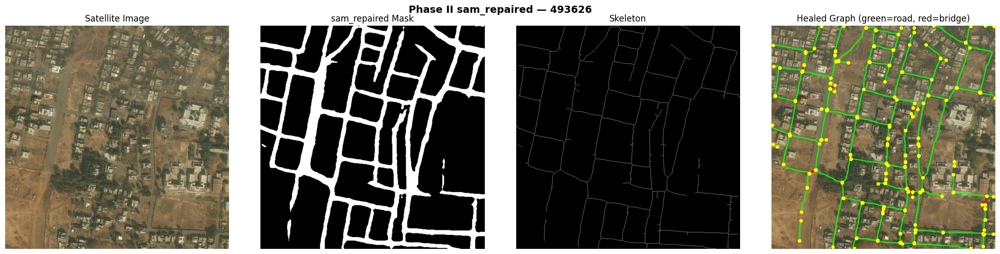

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/493626_phase2.png
[493626] nodes=250 edges=213 bridges=74 connectivity: 0.05 -> 0.32


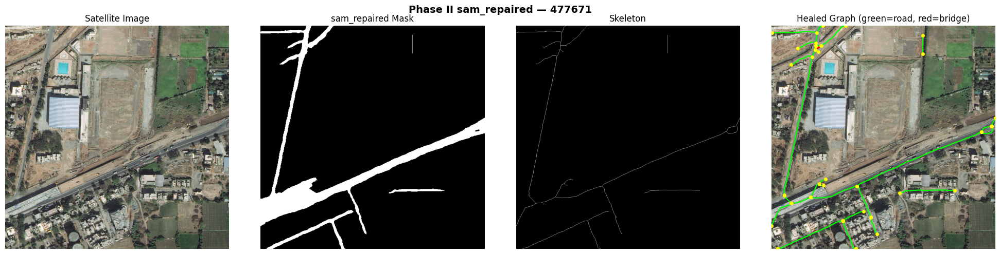

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/477671_phase2.png
[477671] nodes=53 edges=39 bridges=10 connectivity: 0.09 -> 0.23


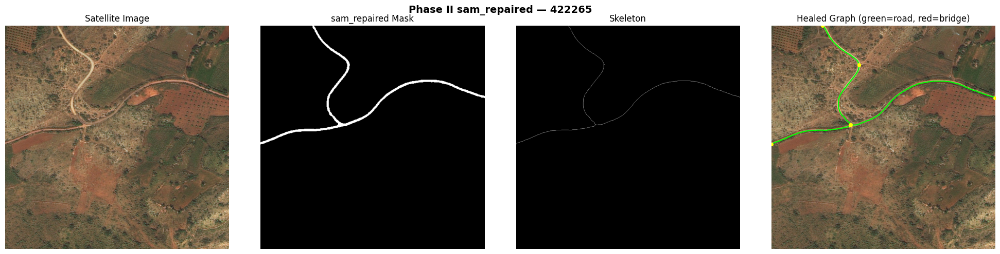

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/422265_phase2.png
[422265] nodes=8 edges=5 bridges=1 connectivity: 0.25 -> 0.50


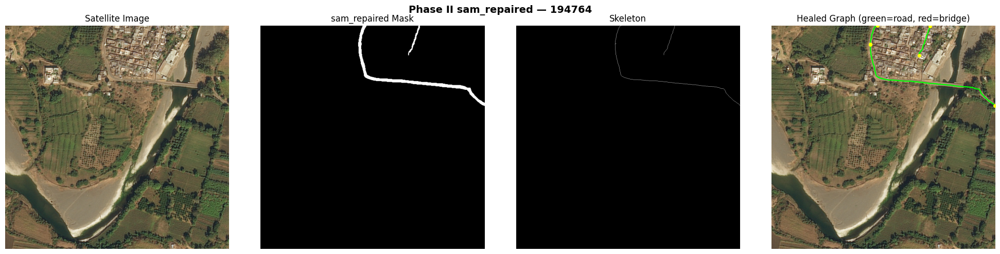

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/194764_phase2.png
[194764] nodes=6 edges=3 bridges=0 connectivity: 0.33 -> 0.33


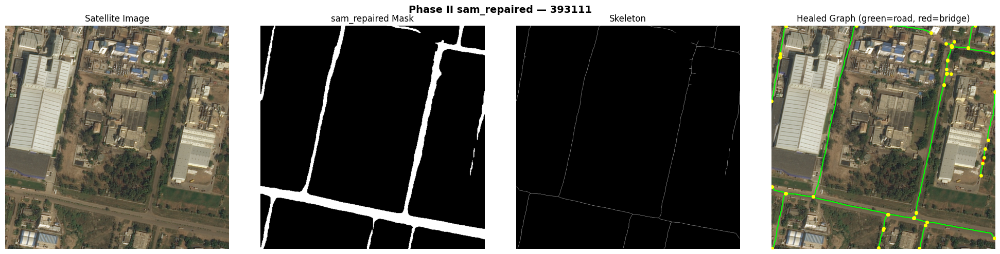

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/393111_phase2.png
[393111] nodes=59 edges=46 bridges=16 connectivity: 0.05 -> 0.22


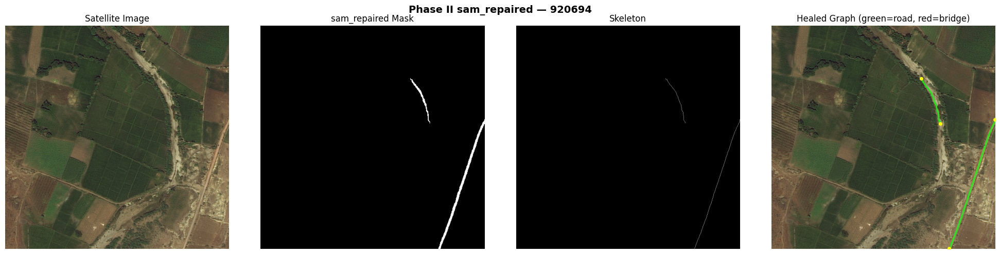

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/920694_phase2.png
[920694] nodes=4 edges=2 bridges=0 connectivity: 0.50 -> 0.50


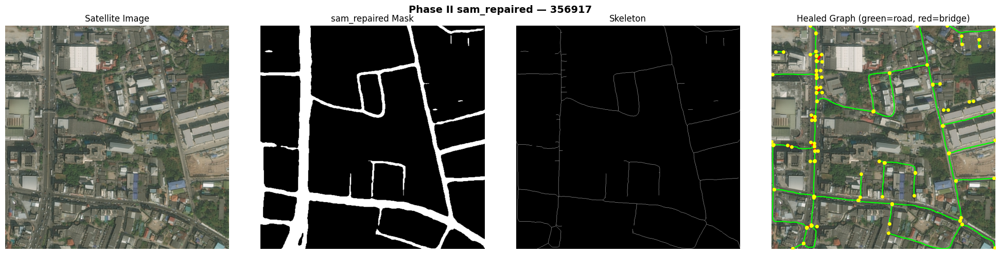

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/356917_phase2.png
[356917] nodes=137 edges=104 bridges=32 connectivity: 0.03 -> 0.16


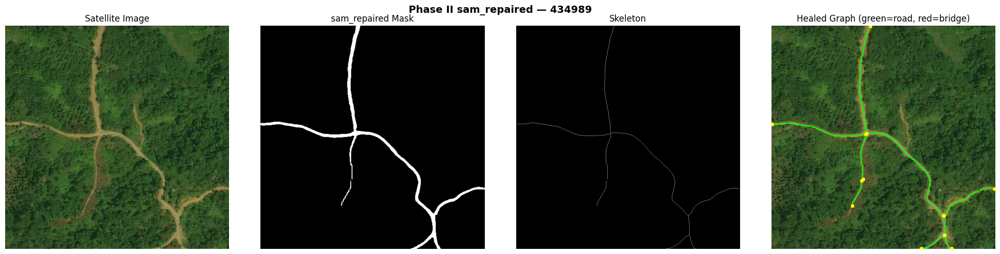

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/434989_phase2.png
[434989] nodes=17 edges=11 bridges=2 connectivity: 0.18 -> 0.24


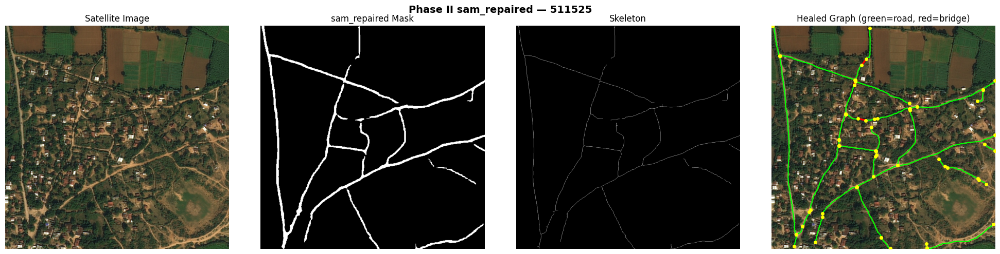

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/511525_phase2.png
[511525] nodes=74 edges=62 bridges=24 connectivity: 0.05 -> 0.30


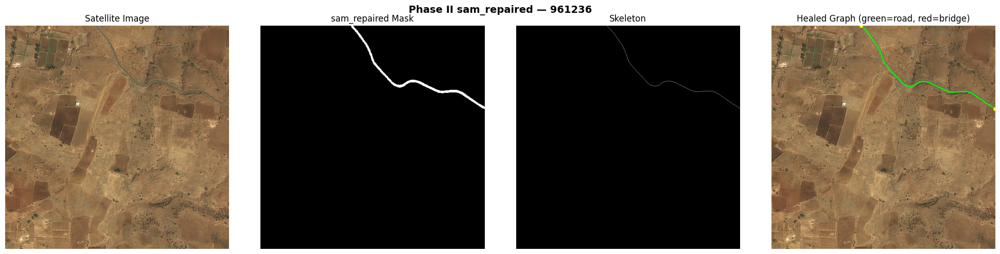

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/961236_phase2.png
[961236] nodes=2 edges=1 bridges=0 connectivity: 1.00 -> 1.00


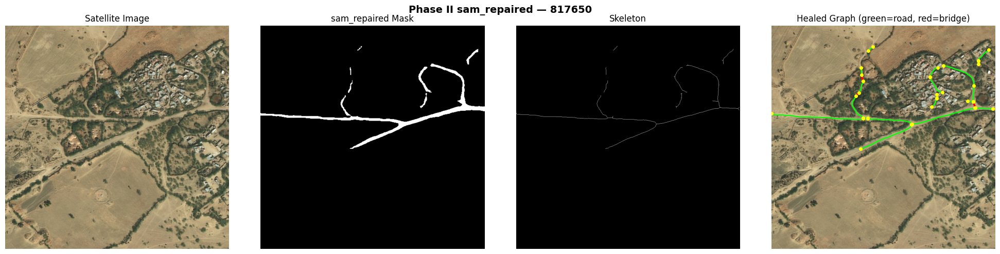

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/817650_phase2.png
[817650] nodes=39 edges=30 bridges=10 connectivity: 0.08 -> 0.36


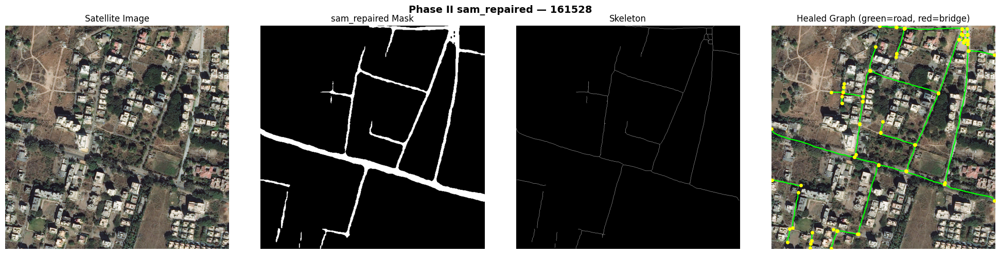

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/161528_phase2.png
[161528] nodes=94 edges=79 bridges=31 connectivity: 0.03 -> 0.39


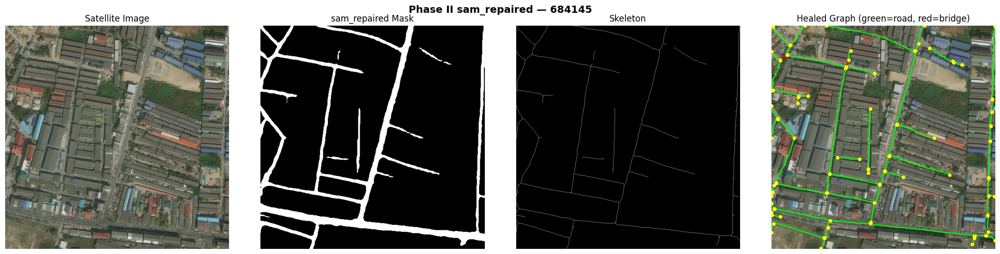

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/684145_phase2.png
[684145] nodes=114 edges=90 bridges=27 connectivity: 0.04 -> 0.15


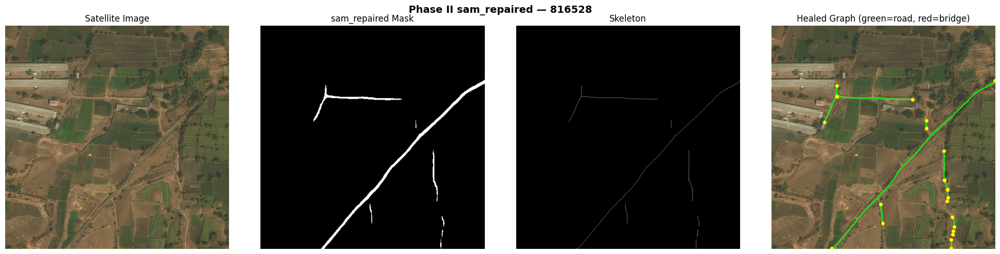

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/816528_phase2.png
[816528] nodes=25 edges=18 bridges=5 connectivity: 0.12 -> 0.28


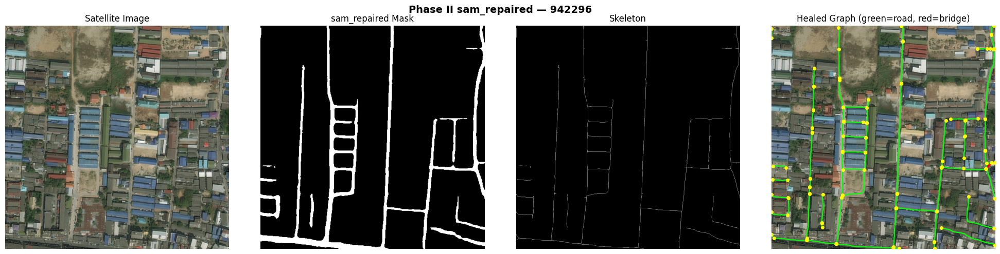

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/942296_phase2.png
[942296] nodes=129 edges=108 bridges=37 connectivity: 0.05 -> 0.21


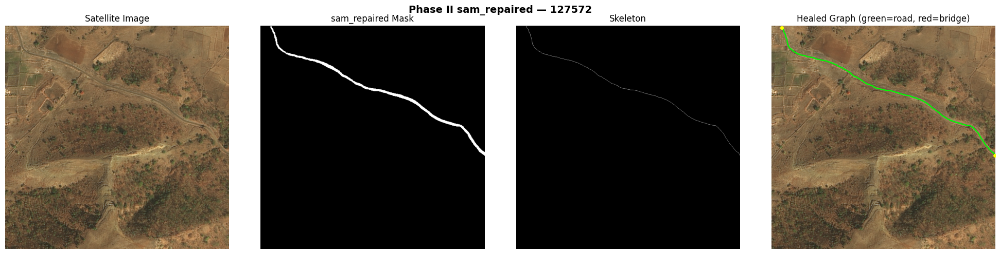

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/127572_phase2.png
[127572] nodes=2 edges=1 bridges=0 connectivity: 1.00 -> 1.00


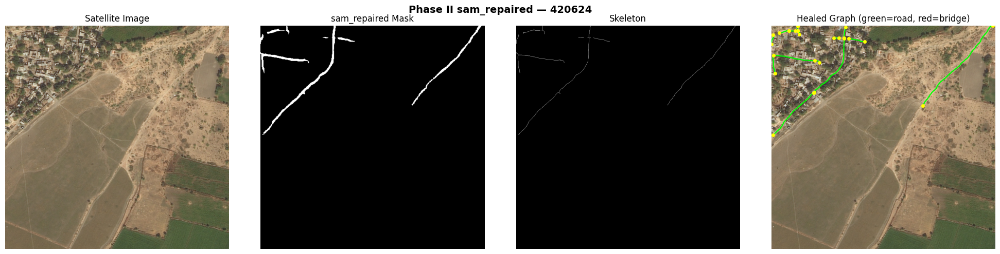

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/420624_phase2.png
[420624] nodes=27 edges=18 bridges=4 connectivity: 0.11 -> 0.22


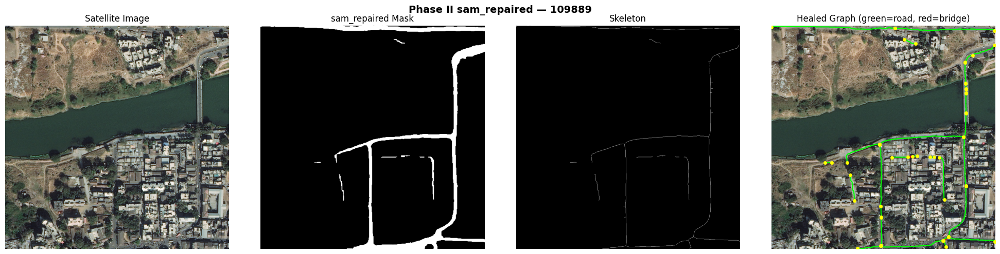

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/109889_phase2.png
[109889] nodes=55 edges=42 bridges=14 connectivity: 0.05 -> 0.25


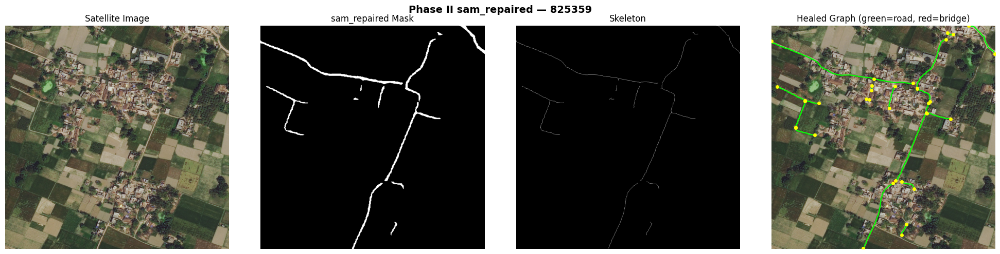

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/825359_phase2.png
[825359] nodes=37 edges=22 bridges=3 connectivity: 0.08 -> 0.16


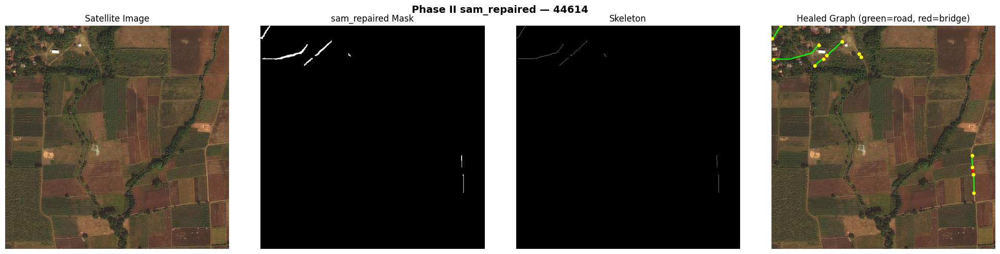

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/44614_phase2.png
[44614] nodes=14 edges=9 bridges=2 connectivity: 0.14 -> 0.29


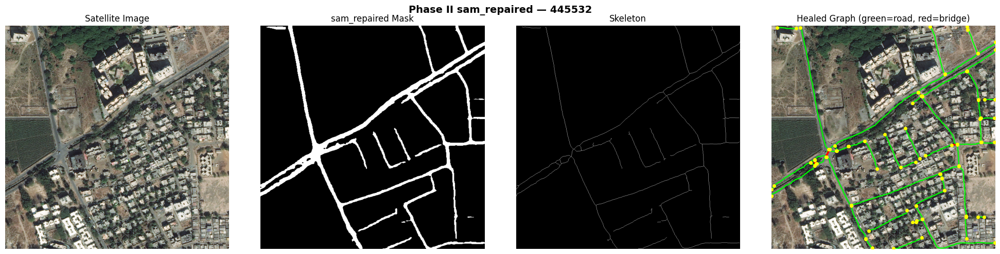

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/445532_phase2.png
[445532] nodes=109 edges=86 bridges=28 connectivity: 0.04 -> 0.28


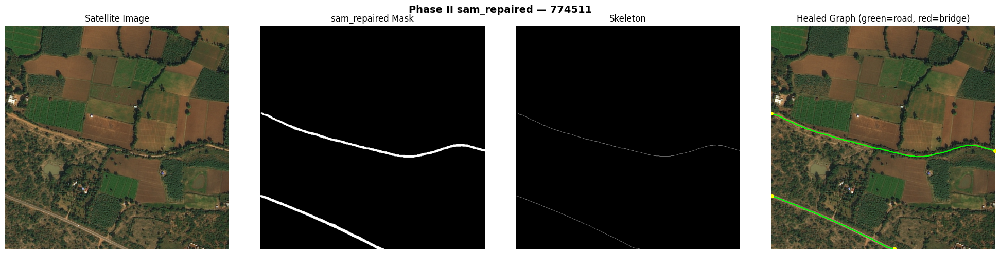

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/774511_phase2.png
[774511] nodes=4 edges=2 bridges=0 connectivity: 0.50 -> 0.50


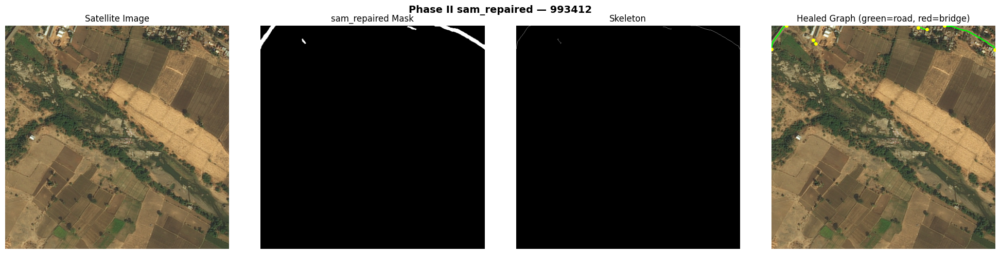

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/993412_phase2.png
[993412] nodes=8 edges=4 bridges=0 connectivity: 0.25 -> 0.25


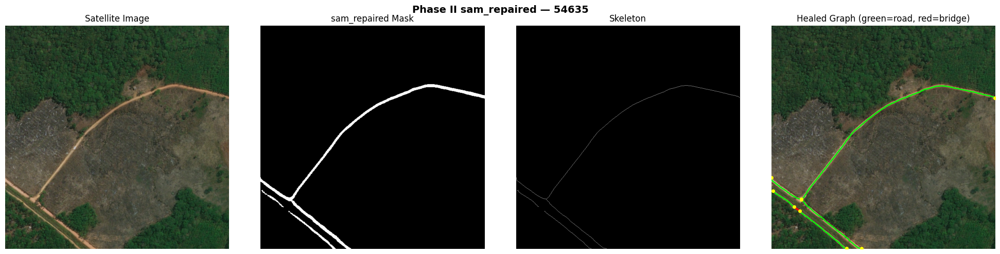

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/54635_phase2.png
[54635] nodes=10 edges=7 bridges=2 connectivity: 0.20 -> 0.40


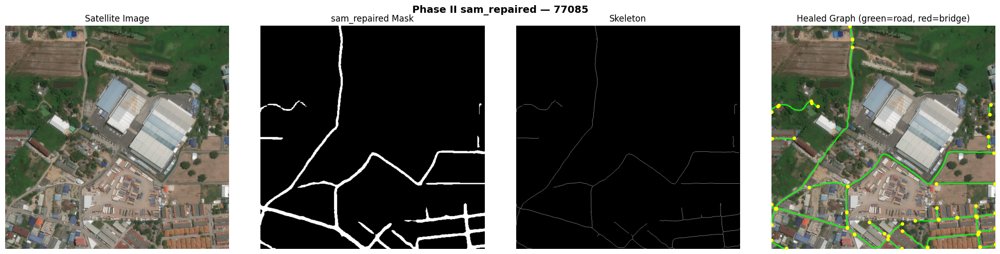

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/77085_phase2.png
[77085] nodes=68 edges=48 bridges=13 connectivity: 0.04 -> 0.13


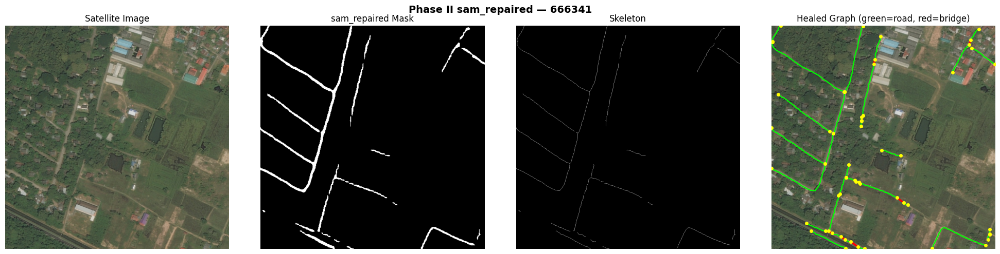

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/666341_phase2.png
[666341] nodes=59 edges=45 bridges=14 connectivity: 0.08 -> 0.14


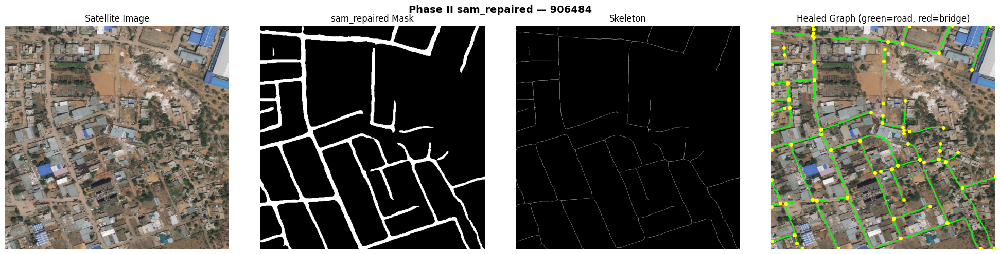

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/906484_phase2.png
[906484] nodes=136 edges=105 bridges=33 connectivity: 0.04 -> 0.16


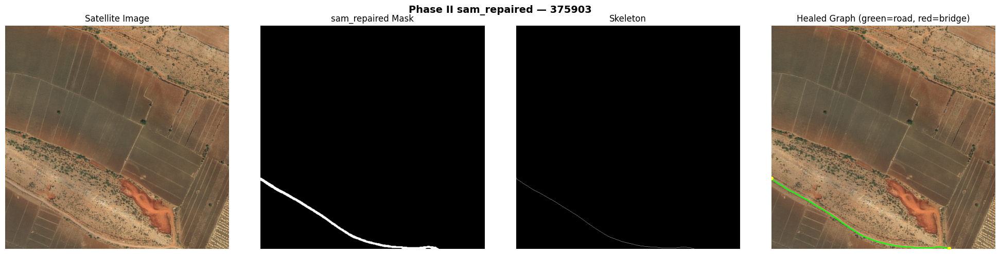

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/375903_phase2.png
[375903] nodes=2 edges=1 bridges=0 connectivity: 1.00 -> 1.00


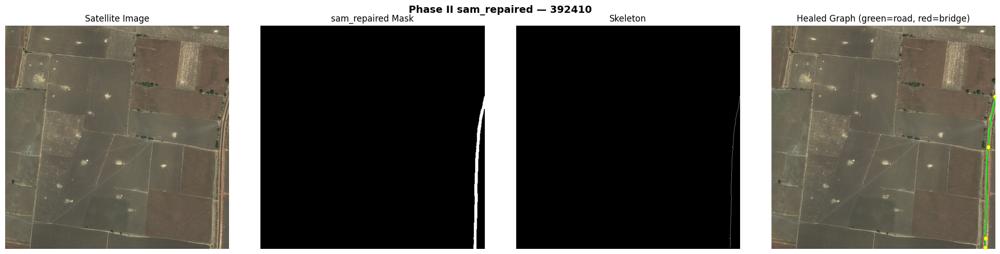

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/392410_phase2.png
[392410] nodes=6 edges=5 bridges=2 connectivity: 0.33 -> 1.00


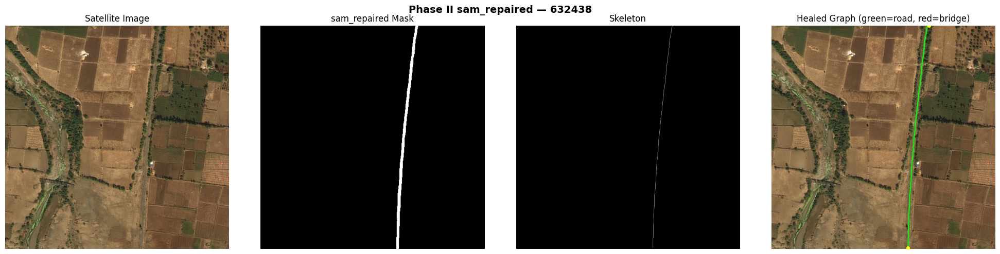

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/632438_phase2.png
[632438] nodes=2 edges=1 bridges=0 connectivity: 1.00 -> 1.00


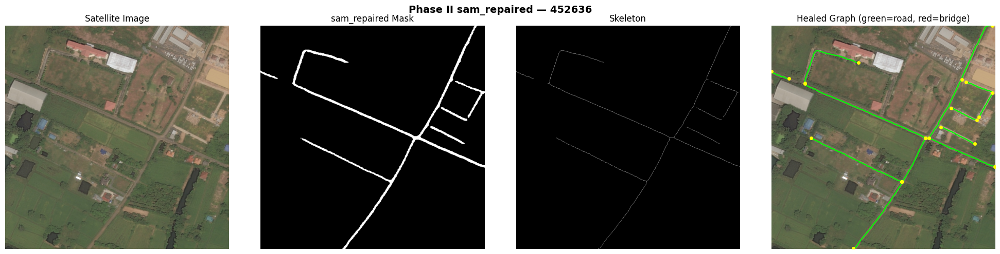

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/452636_phase2.png
[452636] nodes=24 edges=16 bridges=2 connectivity: 0.21 -> 0.29


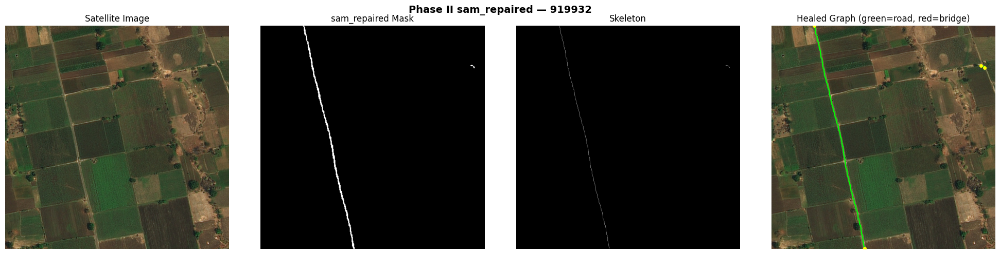

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/919932_phase2.png
[919932] nodes=4 edges=2 bridges=0 connectivity: 0.50 -> 0.50


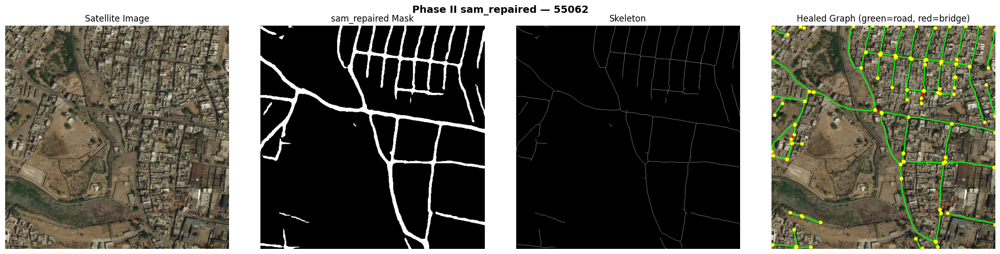

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/55062_phase2.png
[55062] nodes=140 edges=114 bridges=40 connectivity: 0.04 -> 0.29


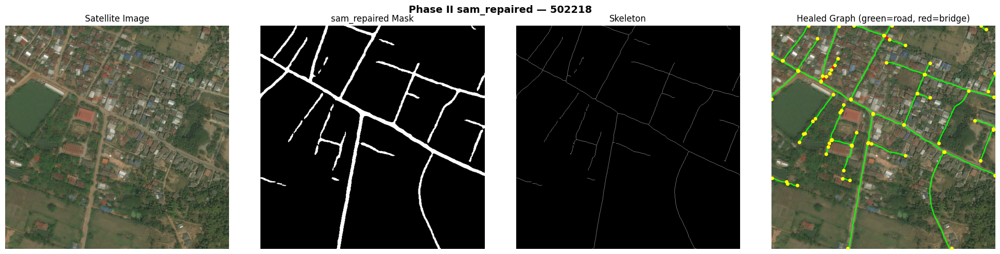

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/502218_phase2.png
[502218] nodes=93 edges=70 bridges=21 connectivity: 0.04 -> 0.17


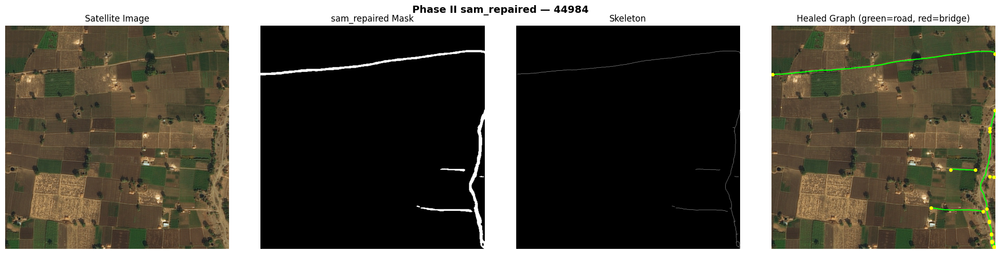

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/44984_phase2.png
[44984] nodes=21 edges=16 bridges=5 connectivity: 0.14 -> 0.62


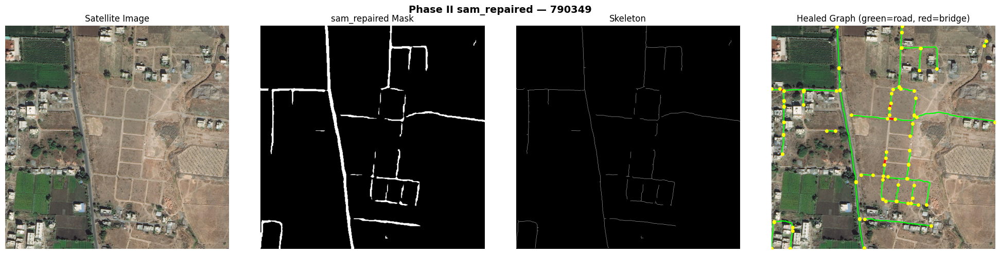

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/790349_phase2.png
[790349] nodes=96 edges=69 bridges=21 connectivity: 0.02 -> 0.10


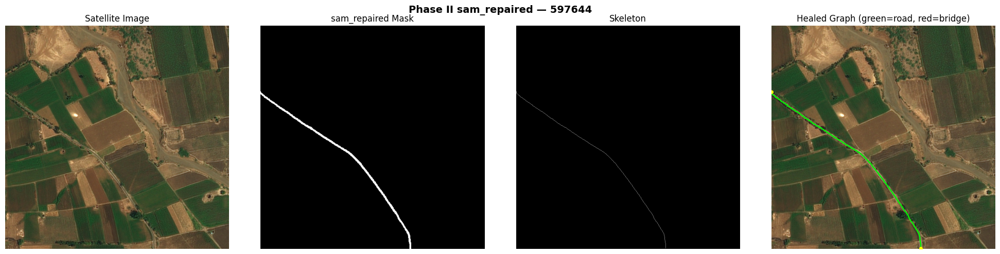

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/597644_phase2.png
[597644] nodes=2 edges=1 bridges=0 connectivity: 1.00 -> 1.00


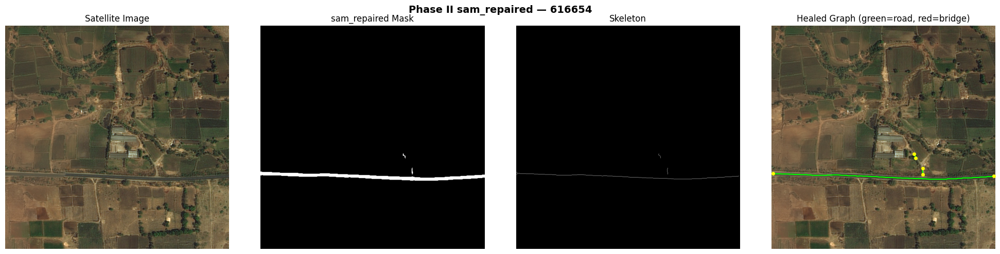

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/616654_phase2.png
[616654] nodes=6 edges=3 bridges=0 connectivity: 0.33 -> 0.33


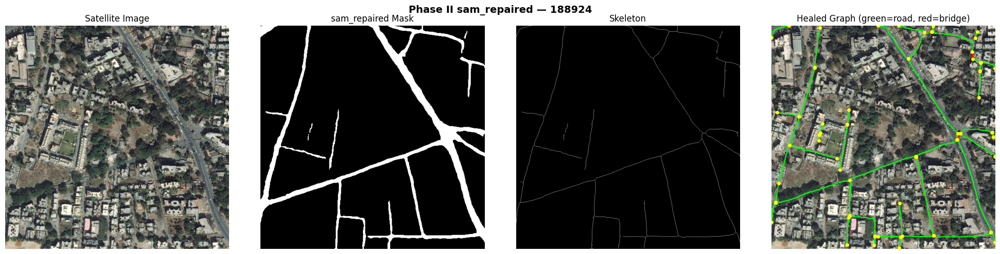

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/188924_phase2.png
[188924] nodes=80 edges=62 bridges=18 connectivity: 0.06 -> 0.14


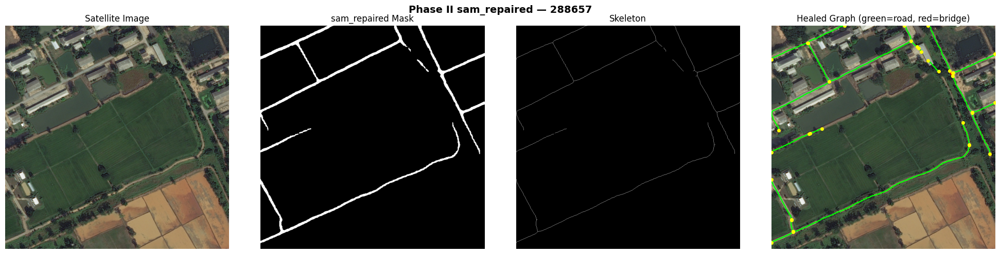

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/288657_phase2.png
[288657] nodes=40 edges=30 bridges=8 connectivity: 0.15 -> 0.20


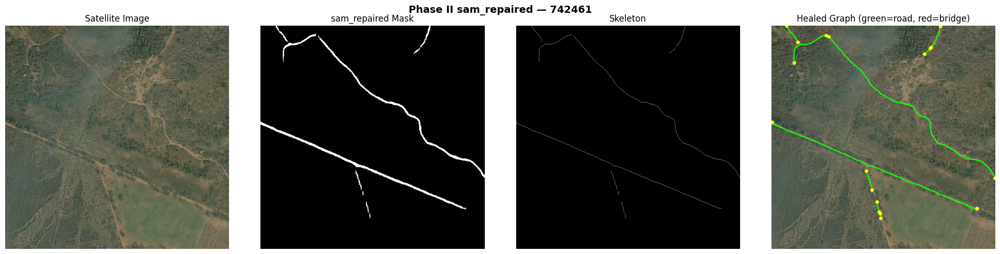

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/742461_phase2.png
[742461] nodes=18 edges=11 bridges=2 connectivity: 0.11 -> 0.22


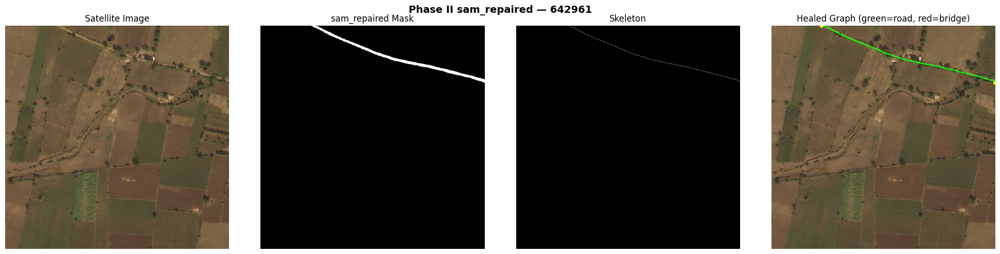

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/642961_phase2.png
[642961] nodes=2 edges=1 bridges=0 connectivity: 1.00 -> 1.00


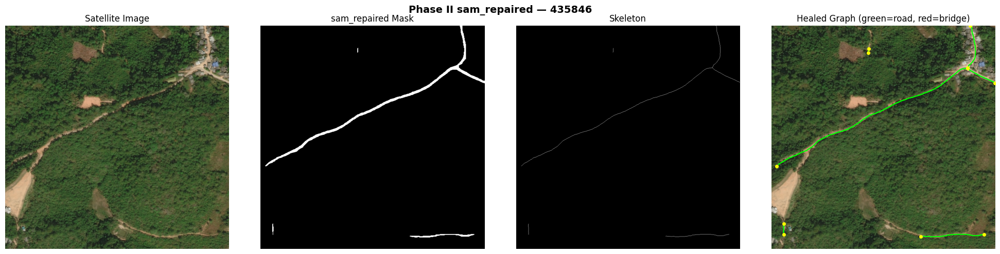

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/435846_phase2.png
[435846] nodes=12 edges=6 bridges=0 connectivity: 0.17 -> 0.17


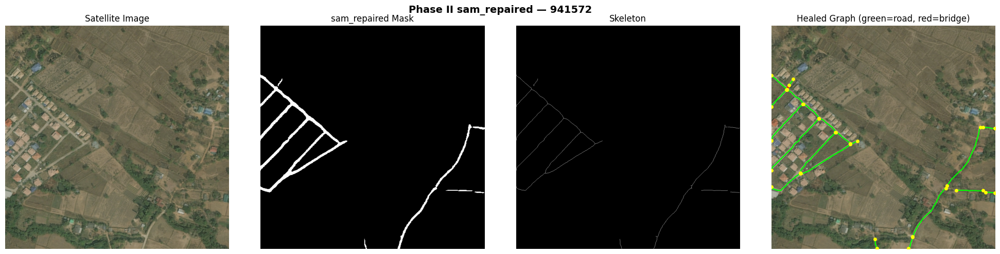

Saved: /content/drive/MyDrive/RouteResilience/outputs/visualizations_sam_repaired/941572_phase2.png
[941572] nodes=40 edges=31 bridges=11 connectivity: 0.05 -> 0.25

results:
ID            Nodes  Edges  Bridges  Conn Before  Conn After
------------------------------------------------------------
493626          250    213       74        0.052       0.324
477671           53     39       10        0.094       0.226
422265            8      5        1        0.250       0.500
194764            6      3        0        0.333       0.333
393111           59     46       16        0.051       0.220
920694            4      2        0        0.500       0.500
356917          137    104       32        0.029       0.161
434989           17     11        2        0.176       0.235
511525           74     62       24        0.054       0.297
961236            2      1        0        1.000       1.000
817650           39     30       10        0.077       0.359
161528           94     79      

In [16]:
def export_json(G, image_id, ratio_before, ratio_after, bridges, out_dir=GRAPH_DIR):
    """Write graph JSON for Phase III / dashboard."""
    nodes = [
        {
            "id": f"n{n}",
            "x": G.nodes[n]["x"],
            "y": G.nodes[n]["y"],
            "degree": G.degree(n),
        }
        for n in G.nodes
    ]
    edges = [
        {
            "id": f"e{u}_{v}",
            "source": f"n{u}",
            "target": f"n{v}",
            "weight": data.get("length", 1.0),
            "healed": data.get("healed", False),
            "coords": [[int(p[0]), int(p[1])] for p in data["pts"]],
        }
        for u, v, data in G.edges(data=True)
    ]
    out = {
        "image_id": image_id,
        "model": MODEL_NAME,
        "nodes": nodes,
        "edges": edges,
        "stats": {
            "num_nodes": len(nodes),
            "num_edges": len(edges),
            "connectivity_before": round(ratio_before, 4),
            "connectivity_after": round(ratio_after, 4),
            "bridges_added": len(bridges),
        },
    }
    path = f"{out_dir}/{image_id}_graph.json"
    with open(path, "w") as f:
        json.dump(out, f, indent=2)
    return out


def visualize(sat_img, mask, skel, G, image_id):
    """Save 4-panel PNG."""
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(sat_img)
    axes[0].set_title("Satellite Image")

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title(f"{MODEL_TAG} Mask")

    axes[2].imshow(skel, cmap="gray")
    axes[2].set_title("Skeleton")

    axes[3].imshow(sat_img)
    for u, v, data in G.edges(data=True):
        pts = data["pts"]
        xs = [p[1] for p in pts]
        ys = [p[0] for p in pts]
        color = "red" if data.get("healed") else "lime"
        lw = 2.5 if data.get("healed") else 1.5
        axes[3].plot(xs, ys, color=color, linewidth=lw)
    for n in G.nodes:
        axes[3].plot(
            G.nodes[n]["x"], G.nodes[n]["y"],
            "o", color="yellow", markersize=4,
        )
    axes[3].set_title("Healed Graph (green=road, red=bridge)")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(f"Phase II {MODEL_TAG} — {image_id}", fontsize=14, fontweight="bold")
    plt.tight_layout()
    save_path = f"{VIS_DIR}/{image_id}_phase2.png"
    plt.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()
    print(f"Saved: {save_path}")


def load_mask_for_sat(mask_path, sat_shape):
    """Load mask; resize to satellite image size with INTER_NEAREST if needed."""
    mask = cv2.imread(mask_path, 0)
    if mask is None:
        return None
    h, w = sat_shape[:2]
    if mask.shape[:2] != (h, w):
        mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_NEAREST)
    return mask


# run
import glob
import os

# Force the notebook to ignore the demo IDs and grab every single mask in the folder
PROCESS_IDS = [os.path.basename(path).replace("_pred.png", "") for path in glob.glob(f"{MASK_DIR}/*_pred.png")]

# run
results = []
results = []

for img_id in PROCESS_IDS:
    mask_path = f"{MASK_DIR}/{img_id}_pred.png"
    sat_path = f"{DATA_DIR}/{img_id}_sat.jpg"

    if not os.path.exists(mask_path):
        print(f"SKIP {img_id} — mask not found at {mask_path}")
        continue
    if not os.path.exists(sat_path):
        print(f"SKIP {img_id} — satellite image not found")
        continue

    sat_img = cv2.cvtColor(cv2.imread(sat_path), cv2.COLOR_BGR2RGB)
    mask = load_mask_for_sat(mask_path, sat_img.shape)
    if mask is None:
        print(f"SKIP {img_id} — could not read mask")
        continue

    skel, clean = extract_skeleton(mask)
    G = build_graph(skel)
    G = prune_spurs(G, MIN_SPUR_LENGTH)
    ratio_before = conn_ratio(G)
    G, bridges = heal_graph(G)
    ratio_after = conn_ratio(G)

    export_json(G, img_id, ratio_before, ratio_after, bridges)
    visualize(sat_img, clean, skel, G, img_id)

    results.append({
        "id": img_id,
        "nodes": G.number_of_nodes(),
        "edges": G.number_of_edges(),
        "bridges": len(bridges),
        "connectivity_before": round(ratio_before, 3),
        "connectivity_after": round(ratio_after, 3),
    })
    print(
        f"[{img_id}] nodes={G.number_of_nodes()} edges={G.number_of_edges()} "
        f"bridges={len(bridges)} connectivity: {ratio_before:.2f} -> {ratio_after:.2f}"
    )

print("\nresults:")
print(f"{'ID':<12} {'Nodes':>6} {'Edges':>6} {'Bridges':>8} {'Conn Before':>12} {'Conn After':>11}")
print("-" * 60)
for r in results:
    print(
        f"{r['id']:<12} {r['nodes']:>6} {r['edges']:>6} {r['bridges']:>8} "
        f"{r['connectivity_before']:>12.3f} {r['connectivity_after']:>11.3f}"
    )

if results:
    avg_before = np.mean([r["connectivity_before"] for r in results])
    avg_after = np.mean([r["connectivity_after"] for r in results])
    print(f"\nAvg connectivity: {avg_before:.3f} -> {avg_after:.3f}")

print(f"\nGraphs saved to: {GRAPH_DIR}")
print(f"Visualizations saved to: {VIS_DIR}")


## Outputs

After a full run you should see:

- `outputs/graphs_<MODEL_TAG>/{id}_graph.json` — nodes, edges, coords, healed flag, and which model produced the source mask
- `outputs/visualizations_<MODEL_TAG>/{id}_phase2.png` — 4-panel figure for slides

Phase III reads the JSON files. If bridges look wrong, tweak `MAX_BRIDGE_DIST` in the config cell (40 px default).

To compare architectures, just change `MODEL_NAME` and re-run from the model-switch cell down — each run writes to its own `graphs_<tag>` / `visualizations_<tag>` folder, so nothing gets overwritten.
